# Notebook 2 — Mô hình dự báo, đánh giá và khả năng dùng trong vận hành (8 BA)

**Ba research questions của dự án (giữ nguyên):**

* **RQ1.** How consistent are the two EIA-930 sources, and what structure (scale, seasonality, CO2 link) does hourly demand have?
* **RQ2.** How well do models forecast demand 24 h ahead against naive baselines, and do they hold up over time and on unseen balancing authorities?
* **RQ3.** Can the forecast be used operationally: interval coverage, warning of extreme hours, regime change, and does CO2 help?

**Notebook này trả lời RQ2 và RQ3** (RQ1 đã được trả lời ở Notebook 1). Dữ liệu và phạm vi tám BA lấy hoàn toàn từ `data/processed/manifest_8ba.json` do Notebook 1 tạo; notebook này kiểm tra lại checksum và không tự chọn BA.

| Phần | Mục | Nội dung | RQ |
|---|---|---|---|
| A | 1–2 | Nạp dữ liệu, thiết lập dự báo, cách chia train/validation/test | RQ2 |
| A | 3 | Naive baselines | RQ2 |
| A | 4 | Huấn luyện, chọn mô hình trên validation | RQ2 |
| A | 5–6 | Kết quả tổng hợp và theo từng BA | RQ2 |
| A | 7 | Tổng quát hóa: rolling-origin và leave-one-BA-out | RQ2 |
| A | 8 | Mô hình dựa vào đặc trưng nào (importance/SHAP) | RQ2 |
| B | 9 | Khoảng dự báo (conformal): coverage | RQ3 |
| B | 10 | Cảnh báo giờ cực đoan | RQ3 |
| B | 11 | Độ bền theo thời gian / regime change | RQ3 |
| B | 12 | CO2 ablation | RQ3 |
| | 13–14 | Giới hạn, kết luận và bảng kiểm tra | RQ2, RQ3 |

**Quy ước.** Markdown bằng tiếng Việt; chữ trong biểu đồ và bảng bằng tiếng Anh. Kết luận chỉ được viết ra *sau khi* có số liệu; các đoạn "Kết quả" bên dưới sinh từ số vừa tính. Đặt `FAST_MODE = True` ở cell đầu để chạy thử nhanh (mô hình nhỏ, ít seed); kết quả báo cáo phải dùng `False`.

# PHẦN A — RQ2: dự báo trước 24 giờ có tốt hơn naive baseline không?

## 1. Nạp dữ liệu và xác nhận phạm vi tám BA

**Câu hỏi.** Dữ liệu có đúng là thứ Notebook 1 đã kiểm tra, và có đúng tám BA không?
**Cách làm.** Đọc manifest, tính lại MD5 của file đặc trưng, kiểm tra danh sách BA, lấy horizon và ranh giới test từ manifest (không gõ lại).

In [1]:
import json, hashlib, os, pathlib, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import average_precision_score, mean_absolute_error
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore", category=DeprecationWarning)

try:
    from lightgbm import LGBMRegressor
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("LƯU Ý: chưa cài lightgbm nên LightGBM_global sẽ bị bỏ qua và ghi rõ là không có.")
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
    print("LƯU Ý: chưa cài shap nên chỉ dùng permutation importance (không tự động cài đặt).")

plt.rcParams.update({"axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})
REPORT_DIR = "report"; pathlib.Path(REPORT_DIR).mkdir(exist_ok=True)
SEED = 42; np.random.seed(SEED)
SEEDS = [0, 1, 2, 3, 4]          # như dự án gốc
FAST_MODE = False                # True = mô hình nhỏ, ít seed để chạy thử nhanh; để False khi báo cáo kết quả
if FAST_MODE:
    SEEDS = [0, 1]

VALIDATION = []
def check(name, cond, evidence, remaining="", soft=False):
    """Ghi một phép kiểm tra. soft=False: dừng nếu FAIL; soft=True: chỉ ghi WARN."""
    VALIDATION.append({"Validation_Check": name, "Status": "PASS" if cond else ("WARN" if soft else "FAIL"), "Evidence": evidence, "Remaining_Issue": remaining})
    if not cond and not soft:
        raise AssertionError(f"{name}: {evidence}")

MAN_PATH = "data/processed/manifest_8ba.json"
if not os.path.exists(MAN_PATH):
    raise FileNotFoundError(f"Không thấy {MAN_PATH}. Hãy chạy Notebook 1 (new1_8BA_simplified.ipynb) trước.")
man = json.load(open(MAN_PATH))
if not os.path.exists(man["handoff_file"]):
    raise FileNotFoundError(f"Thiếu file đặc trưng {man['handoff_file']} ghi trong manifest.")
md5_now = hashlib.md5(open(man["handoff_file"], "rb").read()).hexdigest()
check("Feature file matches manifest checksum", md5_now == man["md5"], f"md5 {md5_now[:8]}... == manifest {man['md5'][:8]}...",
      "Chạy lại Notebook 1 nếu lỗi; không sửa file bằng tay.")

df_all = pd.read_parquet(man["handoff_file"]) if man["handoff_format"] == "parquet" else pd.read_csv(man["handoff_file"])
UNIT_COL, TIME_COL, TARGET_COL = man["unit_col"], man["time_col"], man["target_col"]
HORIZONS, TEST_START, EVENT_QUANTILE = man["horizons"], man["test_start"], man["event_quantile"]
H = HORIZONS[0]; Y = f"y_h{H}"
for c in (TIME_COL, "target_time_utc"):
    df_all[c] = pd.to_datetime(df_all[c]).astype("datetime64[ns]")
BA_LIST = man["ba_list"]; BA_NAMES = man["ba_names"]

check("Exactly eight BAs in the manifest", len(BA_LIST) == 8, f"{BA_LIST}")
check("Feature table contains exactly the manifest BAs", set(df_all[UNIT_COL].unique()) == set(BA_LIST), f"BAs in table: {sorted(df_all[UNIT_COL].unique())}")
check("Horizon and test start as in the original project", HORIZONS == [24] and TEST_START == "2024-07-01", f"HORIZONS={HORIZONS}, TEST_START={TEST_START}")

PALETTE = ["#1B6B6D", "#F4A261", "#264653", "#E76F51", "#2A9D8F", "#8AB17D", "#6D597A", "#B56576"]
BA_COLORS = dict(zip(BA_LIST, PALETTE))
MODEL_COLORS = {"Persistence": "#999999", "WeeklyNaive": "#C9B79C", "EIA_day_ahead": "#6D597A", "Ridge": "#9FBFBF",
                "RandomForest": "#1B6B6D", "LightGBM_global": "#F4A261"}

def savefig(fig, name):
    fig.savefig(f"{REPORT_DIR}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()
def ba_grid(nrows=4, ncols=2, figsize=(13, 12), **kw):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, **kw)
    return fig, dict(zip(BA_LIST, np.atleast_1d(axes).ravel()))

print(f"Đã nạp {len(df_all):,} dòng | BA: {BA_LIST} | lưới {man['grid_start_utc']} -> {man['grid_end_utc']} (UTC) | horizon {H} h | target test từ {TEST_START}")

Đã nạp 210,440 dòng | BA: ['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP', 'PACW', 'PGE', 'SRP'] | lưới 2022-01-01 08:00:00 -> 2025-01-01 08:00:00 (UTC) | horizon 24 h | target test từ 2024-07-01


## 2. Thiết lập dự báo, cách chia dữ liệu và điều kiện đủ dữ liệu

| Hạng mục | Định nghĩa (theo manifest) |
|---|---|
| Thời điểm phát hành | cuối giờ *t* (UTC); demand đến hết *t* đã biết |
| Target | demand tại *t + 24* (`y_h24`, MW), **một target cho mỗi origin theo giờ** |
| Đặc trưng có sẵn tại *t* | demand tại *t*, lag 1/2/3/24/48/168 h, trung bình và độ lệch chuẩn trượt 24 h, hiệu 1 h, lịch của *t*, mã BA (`unit_code`) |
| Không dùng làm đặc trưng chính | dự báo EIA (chỉ so sánh), cột CO2 (thử ở ablation, mục 12) |
| Train | các dòng có **thời điểm target** trước `TEST_START` |
| Validation (chọn mô hình) | 3 tháng cuối của train (`VAL_START` ≤ target < `TEST_START`); mô hình chọn lọc được *fit* trên target trước `VAL_START` |
| Test | các dòng có thời điểm target từ `TEST_START` |

**Chia theo thời gian, không xáo trộn.** Ranh giới đặt theo *thời điểm của target* nên không có target train nào rơi vào giai đoạn test.

**Giới hạn nêu ngay từ đầu.** Mỗi origin theo giờ được chấm cho *một* giờ đích (*t + 24*). Đây không phải đánh giá một lần nộp dự báo day-ahead gồm 24 giá trị mỗi ngày.

In [2]:
unit_code = {ba: i for i, ba in enumerate(sorted(BA_LIST))}
df_all["unit_code"] = df_all[UNIT_COL].map(unit_code)

LAGS_ORIG = ["y_lag1", "y_lag2", "y_lag3", "y_lag24", "y_lag48", "y_lag168"]
CAL_ORIG = ["hr", "dow", "mon", "doy"]
F_ORIG = ["demand"] + LAGS_ORIG + ["y_ma_season", "y_sd_season", "y_diff1"] + CAL_ORIG + ["unit_code"]    # bộ đặc trưng chính, không có CO2
SECONDARY = man["secondary_features"]
missing_cols = [c for c in F_ORIG + SECONDARY + [Y, "eia_fc_target", "y_lag144"] if c not in df_all.columns]
check("All declared feature columns exist", not missing_cols, f"missing: {missing_cols}")
check("Feature columns are the manifest's primary features", set(F_ORIG) - {"unit_code"} <= set(man["primary_features"]), "F_ORIG subset of manifest.primary_features")

TS = pd.Timestamp(TEST_START)
VAL_START = TS - pd.DateOffset(months=3)
data = df_all[df_all["eligible"]].copy().reset_index(drop=True)
train = data[data["target_time_utc"] < TS]
test  = data[data["target_time_utc"] >= TS]
fit_tr = data[data["target_time_utc"] < VAL_START]
val    = data[(data["target_time_utc"] >= VAL_START) & (data["target_time_utc"] < TS)]
for nm, d in [("train", train), ("test", test), ("fit (pre-validation)", fit_tr), ("validation", val)]:
    assert len(d) > 0, f"Tập {nm} rỗng - kiểm tra TEST_START so với phạm vi dữ liệu"
check("Train/validation/test are time-ordered and disjoint by target time",
      fit_tr["target_time_utc"].max() < VAL_START <= val["target_time_utc"].min() and train["target_time_utc"].max() < TS <= test["target_time_utc"].min(),
      f"fit < {VAL_START.date()} <= validation < {TS.date()} <= test; last train target {train['target_time_utc'].max()}, first test target {test['target_time_utc'].min()}")

# kiểm tra target = demand tại t+24 trên dữ liệu đã nạp (ghép theo timestamp)
chk = df_all[[UNIT_COL, TIME_COL, TARGET_COL, Y]].copy(); chk["key"] = chk[TIME_COL] + pd.Timedelta(hours=H)
mm = chk.merge(df_all[[UNIT_COL, TIME_COL, TARGET_COL]].rename(columns={TIME_COL: "key", TARGET_COL: "d_future"}), on=[UNIT_COL, "key"], how="left")
okk = mm[Y].notna() & mm["d_future"].notna()
check("Target = demand at t+24h re-verified on loaded data", bool(np.allclose(mm.loc[okk, Y], mm.loc[okk, "d_future"])), f"{int(okk.sum()):,} rows, all eight BAs")

# ngưỡng "giờ cực đoan" chỉ từ target của giai đoạn train (dùng ở mục 6, 9, 10)
THR = train.groupby(UNIT_COL)[Y].quantile(EVENT_QUANTILE).reindex(BA_LIST)

display(pd.DataFrame([{"Set": nm, "Rows": len(d), "First_Target_UTC": d["target_time_utc"].min(), "Last_Target_UTC": d["target_time_utc"].max()}
                      for nm, d in [("Fit (selection)", fit_tr), ("Validation", val), ("Train (final)", train), ("Test", test)]]))

all_test_window = df_all[(df_all["target_time_utc"] >= TS) & (df_all["target_time_utc"] <= pd.Timestamp(man["grid_end_utc"]))]
elig_ba = (all_test_window.groupby(UNIT_COL).agg(Test_Origins_In_Window=("eligible", "size"), Eligible_Test_Rows=("eligible", "sum"))
           .assign(Ineligible_Rows=lambda d: d.Test_Origins_In_Window - d.Eligible_Test_Rows,
                   Ineligible_Percent=lambda d: (100 * (d.Test_Origins_In_Window - d.Eligible_Test_Rows) / d.Test_Origins_In_Window).round(2)))
display(elig_ba)
check("All eight BAs have eligible test rows", bool((elig_ba["Eligible_Test_Rows"] > 0).all()), f"eligible test rows per BA: {elig_ba['Eligible_Test_Rows'].min():,}-{elig_ba['Eligible_Test_Rows'].max():,}",
      "Dòng không đủ điều kiện là origin có 168 giờ lịch sử hoặc target chứa giờ thiếu.")

,Set,Rows,First_Target_UTC,Last_Target_UTC
0,Fit (selection),154656,2022-01-09 08:00:00,2024-03-31 23:00:00
1,Validation,17443,2024-04-01 00:00:00,2024-06-30 23:00:00
2,Train (final),172099,2022-01-09 08:00:00,2024-06-30 23:00:00
3,Test,34872,2024-07-01 00:00:00,2025-01-01 08:00:00


,Test_Origins_In_Window,Eligible_Test_Rows,Ineligible_Rows,Ineligible_Percent
ba,,,,
AZPS,4425,4424,1,0.02
BPAT,4425,4425,0,0.00
CISO,4425,4233,192,4.34
LDWP,4425,4091,334,7.55
NEVP,4425,4425,0,0.00
PACW,4425,4425,0,0.00
PGE,4425,4425,0,0.00
SRP,4425,4424,1,0.02


**Nhận xét.** Tập train, validation và test sắp theo thời gian và không chồng lấn theo thời điểm target; target được kiểm tra lại bằng ghép timestamp. Bảng cuối cho biết số origin test bị loại vì thiếu dữ liệu ở từng BA. Ngưỡng giờ cực đoan `THR` chỉ dùng target của giai đoạn train.

## 3. Naive baselines

**Câu hỏi.** Mô hình học máy phải vượt qua cái gì thì mới đáng dùng?

**Điểm tinh tế ở horizon 24 giờ.** Target là demand tại *t + 24*. "Cùng giờ hôm trước" của giờ đích là *t + 24 − 24 = t*, tức demand đang quan sát (`demand`). Vì vậy **persistence và "same hour yesterday" là cùng một dự báo**. Bản gốc gọi cột `y_lag24` (demand tại *t − 24*, tức **48 giờ** trước giờ đích) là "seasonal naive"; đó là dự báo yếu hơn và đã bị bỏ khỏi bảng so sánh (chỉ giữ phép kiểm tra bên dưới để chứng minh). Weekly naive đúng là demand tại *t + 24 − 168 = t − 144* (`y_lag144`).

| Baseline | Dự báo cho *t + 24* |
|---|---|
| `Persistence` (= same hour previous day) | demand tại *t* |
| `WeeklyNaive` | demand tại *t − 144 h* (cùng giờ tuần trước của giờ đích) |
| `EIA_day_ahead` | dự báo day-ahead chính thức của EIA cho giờ đích (chỉ để so sánh, thông tin phát hành khác) |

**Metric.** `MAE_MW`, `RMSE_MW` (MW, BA lớn có trọng số lớn hơn); `nMAE_%` = MAE theo % mean demand thực; `sMAPE_%`; `MASE` = sai số chia cho MAE của persistence trên train của chính BA (MASE < 1 nghĩa là tốt hơn persistence trên train, các BA nhìn chung so sánh được); `Bias_MW` = trung bình (dự báo − thực), âm là dự báo thấp.

In [3]:
_c = df_all[[UNIT_COL, TIME_COL, "y_lag24"]].copy(); _c["key"] = _c[TIME_COL] - pd.Timedelta(hours=24)
_m = _c.merge(df_all[[UNIT_COL, TIME_COL, "demand"]].rename(columns={TIME_COL: "key", "demand": "d_prev"}), on=[UNIT_COL, "key"], how="left")
_ok = _m["y_lag24"].notna() & _m["d_prev"].notna()
check("y_lag24 is demand 24 h before the issue hour (48 h before the target)", bool(np.allclose(_m.loc[_ok, "y_lag24"], _m.loc[_ok, "d_prev"])),
      f"{int(_ok.sum()):,} rows verified by timestamp merge; hence for h=24 the same-hour-previous-day forecast is `demand` (persistence), not y_lag24")

MASE_SCALE = (train[Y] - train["demand"]).abs().groupby(train[UNIT_COL]).mean()
display(MASE_SCALE.rename("MASE_scale_MW (train MAE of persistence)").round(1).to_frame())

def score(y, p, ba):
    """MAE, RMSE (MW), nMAE (% mean demand), sMAPE (%), MASE, Bias (mean forecast - actual), n."""
    y, p = np.asarray(y, float), np.asarray(p, float); e = p - y
    sc = pd.Series(ba).map(MASE_SCALE).to_numpy(float)
    return {"MAE_MW": np.mean(np.abs(e)), "RMSE_MW": np.sqrt(np.mean(e ** 2)), "nMAE_%": 100 * np.mean(np.abs(e)) / np.mean(y),
            "sMAPE_%": 100 * np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(p))), "MASE": np.mean(np.abs(e) / sc), "Bias_MW": e.mean(), "n": len(y)}

def day_bootstrap(err_a, err_b, days, n_boot=2000, seed=SEED):
    """Khoảng tin cậy của mean|err_a| - mean|err_b| bằng cách resample nguyên ngày (các giờ trong một ngày phụ thuộc mạnh)."""
    d = pd.DataFrame({"a": np.abs(err_a), "b": np.abs(err_b), "day": pd.Series(days).dt.date.to_numpy()}).groupby("day").agg(sa=("a", "sum"), sb=("b", "sum"), c=("a", "size"))
    sa, sb, c = d["sa"].to_numpy(), d["sb"].to_numpy(), d["c"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(d), size=(n_boot, len(d)))
    diff = sa[idx].sum(1) / c[idx].sum(1) - sb[idx].sum(1) / c[idx].sum(1)
    return np.percentile(diff, [2.5, 50, 97.5]), len(d)

# khung dự báo cho giai đoạn test: mọi mô hình và baseline nằm trên cùng các dòng
P = test[[UNIT_COL, TIME_COL, "target_time_utc", "demand", "eia_fc_target"]].copy().reset_index(drop=True)
P["y"] = test[Y].to_numpy()
P["Persistence"] = test["demand"].to_numpy()
P["WeeklyNaive"] = test["y_lag144"].to_numpy()
P["EIA_day_ahead"] = np.where(test["eia_fc_target"].to_numpy() > 0, test["eia_fc_target"].to_numpy(), np.nan)
BASELINES = ["Persistence", "WeeklyNaive"]
check("Persistence has MASE = 1 on the training rows (scale sanity check)", abs(np.mean(np.abs(train[Y] - train["demand"]) / train[UNIT_COL].map(MASE_SCALE)) - 1) < 1e-9, "MASE of persistence on train = 1.000 by definition")
display(pd.DataFrame({b: score(P["y"], P[b], P[UNIT_COL]) for b in BASELINES}).T.round(3))

,MASE_scale_MW (train MAE of persistence)
ba,
AZPS,189.5
BPAT,270.8
CISO,1238.4
LDWP,167.6
NEVP,180.6
PACW,122.9
PGE,131.6
SRP,189.1


,MAE_MW,RMSE_MW,nMAE_%,sMAPE_%,MASE,Bias_MW,n
Persistence,335.299,746.372,4.787,4.805,1.065,4.009,34872.0
WeeklyNaive,604.893,1331.366,8.636,8.504,1.970,58.499,34872.0


**Đọc bảng.** `MASE` của persistence trên *test* khác 1 vì thước đo MASE lấy từ train; con số này cho thấy test khó hơn hay dễ hơn train đối với baseline. Các mô hình ở mục 4 được chấm trên đúng các dòng này.

## 4. Huấn luyện, chọn mô hình và so sánh

**Câu hỏi.** Họ mô hình nào dự báo tốt nhất, và việc chọn có công bằng không?

**Các mô hình giữ lại:** `Ridge` (tuyến tính, đặc trưng chuẩn hóa), `RandomForest` (bagging), `LightGBM_global` (boosting, nếu đã cài). Hai mô hình cây dùng hai thuật toán khác nhau, để kiểm tra lợi thế so với persistence không phụ thuộc vào một thuật toán duy nhất.
**Đã bỏ:** `LTSF_Linear` (Ridge chỉ trên các lag), vì trùng họ tuyến tính với `Ridge` và buộc code phải xử lý riêng nhiều nhánh; Chronos và LSTM của bản gốc chưa từng chạy được hoặc chấm trên tập con khác nên không so sánh được. Siêu tham số giữ nguyên như dự án gốc.

**Chọn mô hình không nhìn test.** Bản gốc chọn mô hình tốt nhất theo MAE *test* rồi báo cáo đúng MAE đó. Ở đây mỗi mô hình được fit trên target trước `VAL_START`, chấm trên cửa sổ validation 3 tháng, **chỉ validation quyết định mô hình thắng**; mô hình thắng được fit lại trên toàn bộ train và chấm trên test đúng một lần. Mô hình ngẫu nhiên chạy 5 seed trên test; kết quả là mean ± std theo seed.

In [4]:
def make_model(name, seed=0, light=False):
    n_rf = 60 if FAST_MODE else (100 if light else 300)
    n_gb = 200 if FAST_MODE else (400 if light else 800)
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=n_rf, min_samples_leaf=5, n_jobs=-1, random_state=seed)
    if name == "LightGBM_global":
        if not HAS_LGBM: raise ImportError("lightgbm chưa được cài")
        return LGBMRegressor(n_estimators=n_gb, learning_rate=0.03, num_leaves=31, subsample=0.8, colsample_bytree=0.8, random_state=seed, verbose=-1)
    raise ValueError(name)

def cols_for(drop_unit=False):
    return [c for c in F_ORIG if not (drop_unit and c == "unit_code")]

MODELS = ["Ridge", "RandomForest"] + (["LightGBM_global"] if HAS_LGBM else [])
STOCHASTIC = {"RandomForest", "LightGBM_global"}

# 4.1 chọn mô hình trên validation (fit trên target < VAL_START, không có thông tin test)
val_rows, val_models, val_pred = [], {}, {}
for name in MODELS:
    t0 = time.time()
    m = make_model(name, seed=0).fit(fit_tr[cols_for()], fit_tr[Y])
    p = m.predict(val[cols_for()]); val_models[name] = m; val_pred[name] = p
    val_rows.append({"Model": name, **score(val[Y], p, val[UNIT_COL]), "Fit_Seconds": round(time.time() - t0, 1)})
for b, col in [("Persistence", "demand"), ("WeeklyNaive", "y_lag144")]:
    val_rows.append({"Model": b, **score(val[Y], val[col], val[UNIT_COL]), "Fit_Seconds": 0})
val_tbl = pd.DataFrame(val_rows).set_index("Model").sort_values("MAE_MW")
val_tbl.to_csv(f"{REPORT_DIR}/table_nb2_validation_selection.csv")
display(val_tbl.round(3))
SELECTED = val_tbl.loc[MODELS, "MAE_MW"].idxmin()
print(f"Mô hình được chọn theo MAE validation: {SELECTED}")

# 4.2 fit lại trên toàn bộ train; chấm test cho mọi mô hình và seed
runs = []
for name in MODELS:
    seeds = SEEDS if name in STOCHASTIC else [0]
    for s in seeds:
        m = make_model(name, seed=s).fit(train[cols_for()], train[Y])
        p = m.predict(test[cols_for()])
        runs.append({"Model": name, "Seed": s, **score(test[Y], p, test[UNIT_COL])})
        if s == 0:
            P[name] = p
            if name == SELECTED: final_model = m
runs = pd.DataFrame(runs)
runs.to_csv(f"{REPORT_DIR}/table_nb2_test_runs_by_seed.csv", index=False)
check("All models and baselines scored on identical test rows", all(P[c].notna().all() for c in MODELS + BASELINES) and len(P) == len(test),
      f"{len(P):,} test rows; no missing predictions for {MODELS + BASELINES}")
check("No model fitting on validation or test targets (final fits)", train["target_time_utc"].max() < TS and fit_tr["target_time_utc"].max() < VAL_START,
      f"final models fitted on targets < {TS.date()}; selection models on targets < {VAL_START.date()}; scalers live inside sklearn Pipelines fitted on those rows only")

,MAE_MW,RMSE_MW,nMAE_%,sMAPE_%,MASE,Bias_MW,n,Fit_Seconds
Model,,,,,,,,
LightGBM_global,240.100,469.221,3.855,4.122,0.845,-5.811,17443,2.6
RandomForest,245.608,480.019,3.944,4.204,0.867,-14.088,17443,30.2
Ridge,302.747,639.964,4.861,4.867,0.974,-32.473,17443,0.2
Persistence,318.697,680.249,5.117,5.059,1.018,-20.634,17443,0.0
WeeklyNaive,460.313,912.012,7.391,7.778,1.633,-161.129,17443,0.0


Mô hình được chọn theo MAE validation: LightGBM_global


## 5. Kết quả tổng hợp trên test

**Câu hỏi.** Các mô hình so với baseline thế nào trên toàn bộ giai đoạn test?
**Cách làm.** Metric trên toàn bộ test (mean ± std theo seed với mô hình ngẫu nhiên). Dự báo EIA được đưa vào bảng khi nó có trên *mọi* dòng test; nếu chỉ có trên một phần, so sánh được tách ra trên tập con chung. Bootstrap theo *ngày* (đơn vị phụ thuộc), không theo giờ.

Giai đoạn test: 2024-07-01 00:00:00 -> 2025-01-01 08:00:00 | 34,872 dòng | 8 BA | dự báo EIA có trên 100.0% dòng


,MAE_MW_mean,RMSE_MW_mean,nMAE_%_mean,sMAPE_%_mean,MASE_mean,Bias_MW_mean,MAE_MW_std,MASE_std,Seeds
LightGBM_global,271.051,554.801,3.870,4.094,0.925,-34.327,0.307,0.002,5.0
RandomForest,271.088,566.486,3.870,4.097,0.926,-21.477,0.167,0.000,5.0
Ridge,335.192,719.628,4.785,4.895,1.080,7.838,NaN,NaN,1.0
Persistence,335.299,746.372,4.787,4.805,1.065,4.009,NaN,NaN,1.0
EIA_day_ahead,370.407,865.585,5.288,4.657,1.017,-166.994,NaN,NaN,1.0
WeeklyNaive,604.893,1331.366,8.636,8.504,1.970,58.499,NaN,NaN,1.0


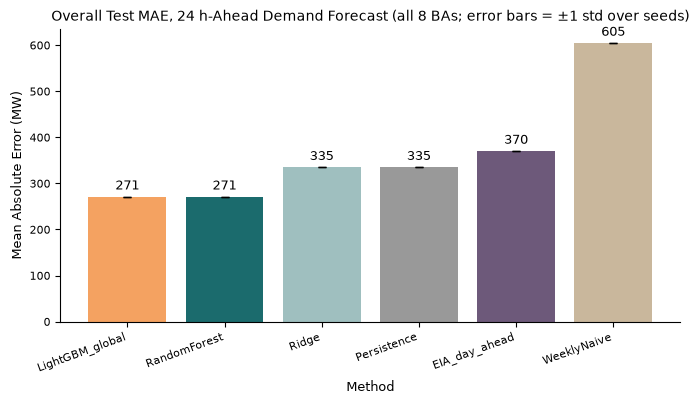

,Comparison,MAE_Difference_MW_Median,CI95_Low,CI95_High,Test_Days,Interpretation
0,LightGBM_global minus Persistence,-64.28,-79.91,-49.01,185,model better (CI below 0)
1,LightGBM_global minus WeeklyNaive,-332.67,-383.12,-286.71,185,model better (CI below 0)
2,LightGBM_global minus EIA_day_ahead,-99.09,-115.01,-84.20,185,model better (CI below 0)


**Kết quả.** Mô hình chọn trên validation là **LightGBM_global**, trên test có MAE 271.1 MW, RMSE 554.8 MW, nMAE 3.87%, MASE 0.925. Persistence có MAE 335.3 MW (MASE 1.065); weekly naive có MAE 604.9 MW. Bootstrap theo ngày cho LightGBM_global trừ persistence: trung vị -64.3 MW (CI 95% -79.9 đến -49.0) → *model better (CI below 0)*. Mô hình tốt nhất trên test là LightGBM_global. Dự báo EIA có MAE 370.4 MW; chênh lệch MAE của LightGBM_global so với EIA là -99.1 MW (CI 95% -115.0 đến -84.2): *model better (CI below 0)*. Đây là so sánh theo giờ đích, không phải cùng tập thông tin (EIA phát hành vào thời điểm riêng).

**Ý nghĩa cho RQ2.** Tuyên bố chính phải là mô hình được chọn trên validation so với *persistence*, baseline trung thực ở horizon này. Con số trung bình toàn bộ test bị các BA lớn chi phối, nên phải xem tiếp bảng từng BA ở mục 6.

In [5]:
agg = (runs.groupby("Model").agg(**{f"{c}_mean": (c, "mean") for c in ["MAE_MW", "RMSE_MW", "nMAE_%", "sMAPE_%", "MASE", "Bias_MW"]},
                                  MAE_MW_std=("MAE_MW", "std"), MASE_std=("MASE", "std"), Seeds=("Seed", "nunique")))
eia_ok = P["EIA_day_ahead"].notna()
full_cov = bool(eia_ok.all())
base_methods = BASELINES + (["EIA_day_ahead"] if full_cov else [])
base_rows = {b: {**{f"{c}_mean": v for c, v in score(P["y"], P[b], P[UNIT_COL]).items() if c != "n"}, "MAE_MW_std": np.nan, "MASE_std": np.nan, "Seeds": 1} for b in base_methods}
overall = pd.concat([agg, pd.DataFrame(base_rows).T]).astype(float).sort_values("MAE_MW_mean")
overall.round(3).to_csv(f"{REPORT_DIR}/table_nb2_overall_comparison.csv")
print(f"Giai đoạn test: {test['target_time_utc'].min()} -> {test['target_time_utc'].max()} | {len(test):,} dòng | 8 BA | dự báo EIA có trên {100 * eia_ok.mean():.1f}% dòng")
display(overall.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
order = overall.index.tolist()
bars = ax.bar(order, overall["MAE_MW_mean"], yerr=overall["MAE_MW_std"].fillna(0), color=[MODEL_COLORS.get(m, "#777777") for m in order], capsize=3)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.set_xlabel("Method"); ax.set_ylabel("Mean Absolute Error (MW)")
ax.set_title("Overall Test MAE, 24 h-Ahead Demand Forecast (all 8 BAs; error bars = ±1 std over seeds)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right"); ax.spines[["top", "right"]].set_visible(False)
savefig(fig, "fig_nb2_overall_mae")

# 5.1 bootstrap theo ngày: mô hình được chọn có tốt hơn các baseline không?
ci_rows = []
for other in BASELINES + (["EIA_day_ahead"] if eia_ok.any() else []):
    msk = eia_ok if other == "EIA_day_ahead" else pd.Series(True, index=P.index)
    (lo, mid, hi), nd = day_bootstrap(P.loc[msk, SELECTED] - P.loc[msk, "y"], P.loc[msk, other] - P.loc[msk, "y"], P.loc[msk, "target_time_utc"])
    ci_rows.append({"Comparison": f"{SELECTED} minus {other}", "MAE_Difference_MW_Median": mid, "CI95_Low": lo, "CI95_High": hi, "Test_Days": nd,
                    "Interpretation": "model better (CI below 0)" if hi < 0 else ("model worse (CI above 0)" if lo > 0 else "no clear difference")})
ci_tbl = pd.DataFrame(ci_rows); ci_tbl.round(2).to_csv(f"{REPORT_DIR}/table_nb2_bootstrap_vs_baselines.csv", index=False); display(ci_tbl.round(2))

if eia_ok.any() and not full_cov:
    sub_methods = ["EIA_day_ahead", SELECTED, "Persistence", "WeeklyNaive"]
    display(pd.DataFrame({m: score(P.loc[eia_ok, "y"], P.loc[eia_ok, m], P.loc[eia_ok, UNIT_COL]) for m in sub_methods}).T.round(3))

sel, pers, wk = overall.loc[SELECTED], overall.loc["Persistence"], overall.loc["WeeklyNaive"]
row = ci_tbl.iloc[0]
best_ml = overall.loc[MODELS, "MAE_MW_mean"].idxmin()
eia_txt = ""
if "EIA_day_ahead" in overall.index:
    e_ = overall.loc["EIA_day_ahead"]; ce = ci_tbl[ci_tbl["Comparison"].str.endswith("EIA_day_ahead")].iloc[0]
    eia_txt = (f" Dự báo EIA có MAE {e_.MAE_MW_mean:,.1f} MW; chênh lệch MAE của {SELECTED} so với EIA là {ce.MAE_Difference_MW_Median:+.1f} MW (CI 95% {ce.CI95_Low:+.1f} đến {ce.CI95_High:+.1f}): *{ce.Interpretation}*. "
               "Đây là so sánh theo giờ đích, không phải cùng tập thông tin (EIA phát hành vào thời điểm riêng).")
display(Markdown(
    f"**Kết quả.** Mô hình chọn trên validation là **{SELECTED}**, trên test có MAE {sel.MAE_MW_mean:,.1f} MW, RMSE {sel.RMSE_MW_mean:,.1f} MW, nMAE {sel['nMAE_%_mean']:.2f}%, MASE {sel.MASE_mean:.3f}. "
    f"Persistence có MAE {pers.MAE_MW_mean:,.1f} MW (MASE {pers.MASE_mean:.3f}); weekly naive có MAE {wk.MAE_MW_mean:,.1f} MW. "
    f"Bootstrap theo ngày cho {SELECTED} trừ persistence: trung vị {row.MAE_Difference_MW_Median:+.1f} MW (CI 95% {row.CI95_Low:+.1f} đến {row.CI95_High:+.1f}) → *{row.Interpretation}*. "
    f"Mô hình tốt nhất trên test là {best_ml}." + eia_txt + "\n\n"
    "**Ý nghĩa cho RQ2.** Tuyên bố chính phải là mô hình được chọn trên validation so với *persistence*, baseline trung thực ở horizon này. Con số trung bình toàn bộ test bị các BA lớn chi phối, nên phải xem tiếp bảng từng BA ở mục 6."))

## 6. Kết quả theo từng BA

**Câu hỏi.** Mô hình có dùng được cho cả tám BA không, BA nào khó nhất và vì sao?
**Cách làm.** Bảng theo BA cho mô hình được chọn và các baseline (MAE, RMSE theo MW; nMAE và MASE theo thước đo độc lập quy mô), hình so sánh ba loại sai số, hình thực tế so với dự báo cho cả tám BA (hai tuần phóng to, kèm persistence), và bảng chẩn đoán nối sai số với quy mô, độ phủ dữ liệu và tỷ lệ giờ cực đoan.

,BA_Name,Test_Rows,MAE_MW_LightGBM_global,MAE_MW_Persistence,RMSE_MW_LightGBM_global,nMAE_%_LightGBM_global,MASE_LightGBM_global,MASE_Persistence,Model_Beats_Persistence,MAE_MW_EIA_day_ahead,Model_Beats_EIA
AZPS,Arizona Public Service Company,4424,200.264,203.932,286.223,4.371,1.057,1.076,True,180.778,False
BPAT,Bonneville Power Administration,4425,192.377,238.105,261.576,2.891,0.710,0.879,True,121.514,False
CISO,California Independent System Operator,4233,1014.678,1406.222,1444.978,3.627,0.819,1.135,True,1824.012,True
LDWP,Los Angeles Department of Water and Power,4091,180.213,203.730,260.589,6.592,1.075,1.216,True,255.061,True
NEVP,Nevada Power Company,4425,189.438,193.847,274.936,3.742,1.049,1.073,True,353.721,True
PACW,PacifiCorp West,4425,91.791,118.829,125.107,3.724,0.747,0.967,True,95.901,True
PGE,Portland General Electric Company,4425,112.102,134.834,164.482,4.230,0.852,1.025,True,31.426,False
SRP,Salt River Project,4424,212.162,219.376,305.766,4.716,1.122,1.160,True,155.113,False


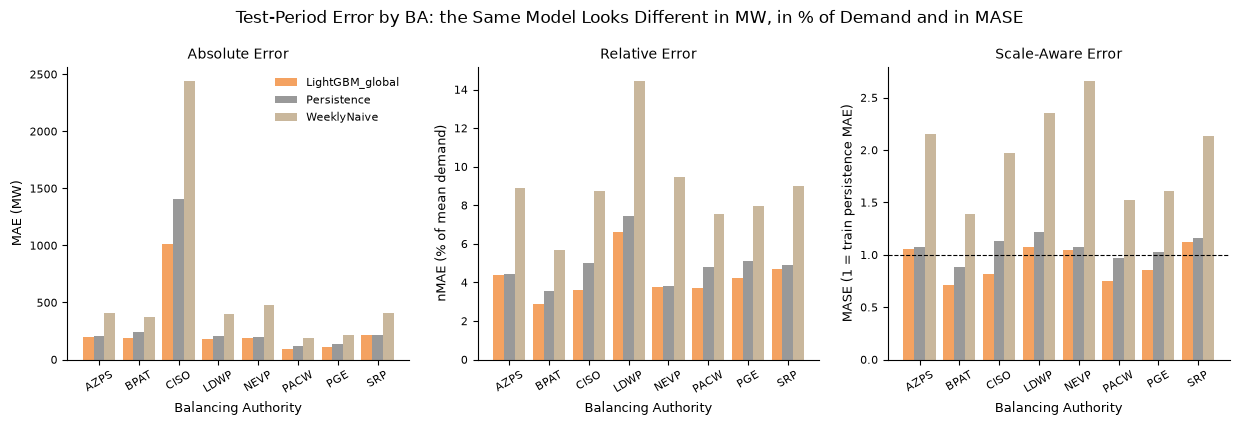

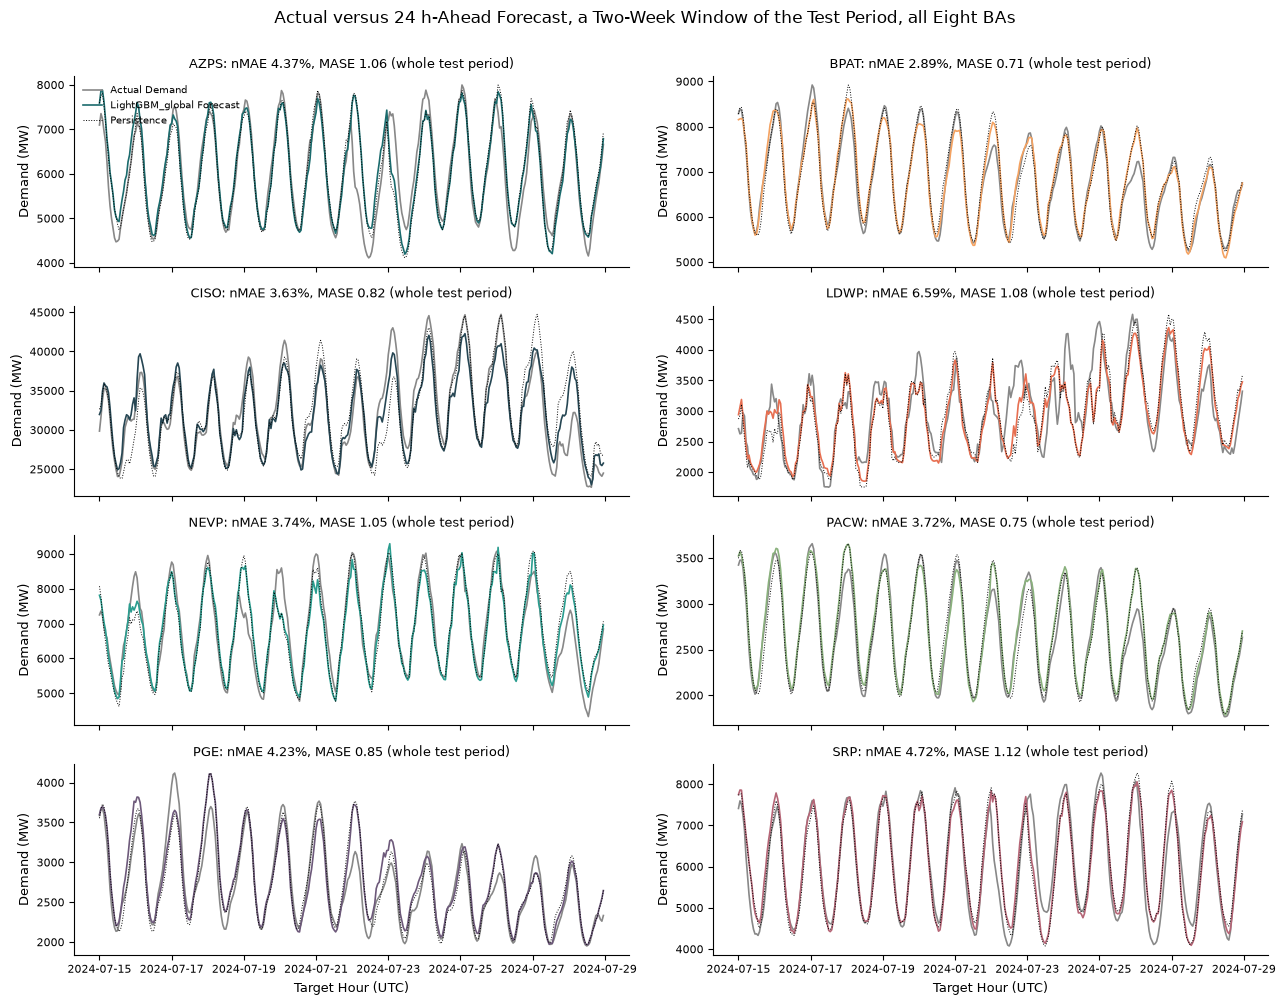

,Mean_Test_Demand_MW,MAE_MW,nMAE_%,MASE,Ineligible_Test_Percent,Share_Extreme_Hours_Test_%,Bias_MW,Coefficient_of_Variation_%,Rank_nMAE (1=easiest),Rank_MASE (1=easiest),Mean_Rank
BPAT,6655.05,192.38,2.89,0.71,0.00,9.4,-25.21,14.2,1,1,1.0
CISO,27975.95,1014.68,3.63,0.82,4.34,26.0,-262.38,18.7,2,3,2.5
PACW,2464.55,91.79,3.72,0.75,0.00,12.5,0.04,17.8,3,2,2.5
NEVP,5062.72,189.44,3.74,1.05,0.00,23.9,-6.02,29.2,4,5,4.5
PGE,2650.25,112.10,4.23,0.85,0.00,14.9,-8.83,16.4,5,4,4.5
AZPS,4581.14,200.26,4.37,1.06,0.02,28.2,15.61,30.4,6,6,6.0
LDWP,2733.65,180.21,6.59,1.08,7.55,13.9,6.30,25.5,8,7,7.5
SRP,4498.82,212.16,4.72,1.12,0.02,25.2,2.61,33.3,7,8,7.5


**Kết quả.** Theo xếp hạng kết hợp nMAE và MASE, BA khó nhất là **SRP** (nMAE 4.72%, MASE 1.12) và dễ nhất là **BPAT** (nMAE 2.89%, MASE 0.71). Tương quan Spearman giữa MAE tuyệt đối và demand trung bình qua 8 BA là 0.79 (chỉ mang tính gợi ý vì n = 8). Mô hình thắng persistence về MAE ở cả tám BA. So với EIA, mô hình thua ở: AZPS, BPAT, PGE, SRP.

**Tìm nguyên nhân ở SRP.** So dòng của nó trong bảng chẩn đoán với các BA khác: hệ số biến thiên (nhu cầu dao động), tỷ lệ giờ cực đoan trong test, tỷ lệ dòng bị loại vì thiếu dữ liệu, và bias. Cột nào nổi bật thì đó là ứng viên giải thích; bảng không tự khẳng định nguyên nhân.

**Ý nghĩa cho RQ2.** Trung bình gộp bị BA lớn chi phối. Chỉ các chỉ số độc lập quy mô theo từng BA (nMAE, MASE) mới cho biết mô hình đáng tin ở đâu và không đáng tin ở đâu.

In [6]:
def per_ba(P_, methods):
    rows = []
    for ba in BA_LIST:
        g = P_[P_[UNIT_COL] == ba]
        for m in methods:
            ok = g[m].notna()
            rows.append({"BA_Code": ba, "Method": m, **score(g.loc[ok, "y"], g.loc[ok, m], g.loc[ok, UNIT_COL])})
    return pd.DataFrame(rows)

METHODS = [SELECTED, "Persistence", "WeeklyNaive"] + (["EIA_day_ahead"] if eia_ok.any() else []) + [m for m in MODELS if m != SELECTED]
pb = per_ba(P, METHODS)
pb.round(3).to_csv(f"{REPORT_DIR}/table_nb2_per_ba_all_methods.csv", index=False)
pb_sel = pb[pb.Method == SELECTED].set_index("BA_Code").reindex(BA_LIST)
pb_per = pb[pb.Method == "Persistence"].set_index("BA_Code").reindex(BA_LIST)
per_ba_main = pd.DataFrame({"BA_Name": [BA_NAMES[b] for b in BA_LIST], "Test_Rows": pb_sel["n"].astype(int).values,
                            f"MAE_MW_{SELECTED}": pb_sel["MAE_MW"].values, "MAE_MW_Persistence": pb_per["MAE_MW"].values,
                            f"RMSE_MW_{SELECTED}": pb_sel["RMSE_MW"].values, f"nMAE_%_{SELECTED}": pb_sel["nMAE_%"].values,
                            f"MASE_{SELECTED}": pb_sel["MASE"].values, "MASE_Persistence": pb_per["MASE"].values,
                            "Model_Beats_Persistence": (pb_sel["MAE_MW"] < pb_per["MAE_MW"]).values}, index=BA_LIST)
if eia_ok.any():
    per_ba_main["MAE_MW_EIA_day_ahead"] = pb[pb.Method == "EIA_day_ahead"].set_index("BA_Code")["MAE_MW"].reindex(BA_LIST).values
    per_ba_main["Model_Beats_EIA"] = per_ba_main[f"MAE_MW_{SELECTED}"] < per_ba_main["MAE_MW_EIA_day_ahead"]
per_ba_main = per_ba_main.round(3)
per_ba_main.to_csv(f"{REPORT_DIR}/table_nb2_per_ba_main.csv")
check("Per-BA table has exactly eight BAs", len(per_ba_main) == 8 and set(per_ba_main.index) == set(BA_LIST), f"{per_ba_main.index.tolist()}")
display(per_ba_main)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(8); w = 0.27
for j, m in enumerate([SELECTED, "Persistence", "WeeklyNaive"]):
    d = pb[pb.Method == m].set_index("BA_Code").reindex(BA_LIST)
    axs[0].bar(x + (j - 1) * w, d["MAE_MW"], w, color=MODEL_COLORS[m], label=m)
    axs[1].bar(x + (j - 1) * w, d["nMAE_%"], w, color=MODEL_COLORS[m], label=m)
    axs[2].bar(x + (j - 1) * w, d["MASE"], w, color=MODEL_COLORS[m], label=m)
axs[2].axhline(1, color="k", ls="--", lw=0.8)
for ax, yl, tt in zip(axs, ["MAE (MW)", "nMAE (% of mean demand)", "MASE (1 = train persistence MAE)"], ["Absolute Error", "Relative Error", "Scale-Aware Error"]):
    ax.set_xticks(x); ax.set_xticklabels(BA_LIST, rotation=30); ax.set_xlabel("Balancing Authority"); ax.set_ylabel(yl); ax.set_title(tt); ax.spines[["top", "right"]].set_visible(False)
axs[0].legend(frameon=False)
fig.suptitle("Test-Period Error by BA: the Same Model Looks Different in MW, in % of Demand and in MASE", y=1.03)
savefig(fig, "fig_nb2_per_ba_error")

ZOOM_START = P["target_time_utc"].min() + pd.Timedelta(days=14); ZOOM_END = ZOOM_START + pd.Timedelta(days=14)
fig, axs = ba_grid(4, 2, figsize=(13, 10), sharex=True)
for ba, ax in axs.items():
    g = P[(P[UNIT_COL] == ba) & (P["target_time_utc"] >= ZOOM_START) & (P["target_time_utc"] < ZOOM_END)].sort_values("target_time_utc")
    ax.plot(g["target_time_utc"], g["y"], color="#888888", lw=1.2, label="Actual Demand")
    ax.plot(g["target_time_utc"], g[SELECTED], color=BA_COLORS[ba], lw=1.2, label=f"{SELECTED} Forecast")
    ax.plot(g["target_time_utc"], g["Persistence"], color="k", lw=0.7, ls=":", label="Persistence")
    ax.set_title(f"{ba}: nMAE {pb_sel.loc[ba, 'nMAE_%']:.2f}%, MASE {pb_sel.loc[ba, 'MASE']:.2f} (whole test period)", fontsize=9)
    ax.set_ylabel("Demand (MW)"); ax.spines[["top", "right"]].set_visible(False)
list(axs.values())[0].legend(frameon=False, fontsize=7, loc="upper left")
for ax in list(axs.values())[-2:]: ax.set_xlabel("Target Hour (UTC)")
fig.suptitle("Actual versus 24 h-Ahead Forecast, a Two-Week Window of the Test Period, all Eight BAs", y=1.0)
fig.tight_layout(); savefig(fig, "fig_nb2_actual_vs_pred_zoom")

P["ext"] = (P["y"] > P[UNIT_COL].map(THR)).to_numpy()
diag = pd.DataFrame({
    "Mean_Test_Demand_MW": P.groupby(UNIT_COL)["y"].mean(), "MAE_MW": pb_sel["MAE_MW"], "nMAE_%": pb_sel["nMAE_%"], "MASE": pb_sel["MASE"],
    "Ineligible_Test_Percent": elig_ba["Ineligible_Percent"], "Share_Extreme_Hours_Test_%": (100 * P.groupby(UNIT_COL)["ext"].mean()).round(1),
    "Bias_MW": pb_sel["Bias_MW"], "Coefficient_of_Variation_%": (100 * P.groupby(UNIT_COL)["y"].std() / P.groupby(UNIT_COL)["y"].mean()).round(1)}).loc[BA_LIST]
diag["Rank_nMAE (1=easiest)"] = diag["nMAE_%"].rank().astype(int)
diag["Rank_MASE (1=easiest)"] = diag["MASE"].rank().astype(int)
diag["Mean_Rank"] = (diag["Rank_nMAE (1=easiest)"] + diag["Rank_MASE (1=easiest)"]) / 2
diag = diag.sort_values("Mean_Rank"); diag.round(3).to_csv(f"{REPORT_DIR}/table_nb2_difficulty_ranking.csv")
display(diag.round(2))

hardest, easiest = diag.index[-1], diag.index[0]
bad_vs_pers = per_ba_main.index[~per_ba_main["Model_Beats_Persistence"].astype(bool)].tolist()
bad_vs_eia = per_ba_main.index[~per_ba_main["Model_Beats_EIA"].astype(bool)].tolist() if "Model_Beats_EIA" in per_ba_main else []
corr_scale = diag[["Mean_Test_Demand_MW", "MAE_MW"]].corr(method="spearman").iloc[0, 1]
display(Markdown(
    f"**Kết quả.** Theo xếp hạng kết hợp nMAE và MASE, BA khó nhất là **{hardest}** (nMAE {diag.loc[hardest, 'nMAE_%']:.2f}%, MASE {diag.loc[hardest, 'MASE']:.2f}) và dễ nhất là **{easiest}** "
    f"(nMAE {diag.loc[easiest, 'nMAE_%']:.2f}%, MASE {diag.loc[easiest, 'MASE']:.2f}). Tương quan Spearman giữa MAE tuyệt đối và demand trung bình qua 8 BA là {corr_scale:.2f} (chỉ mang tính gợi ý vì n = 8). "
    f"Mô hình {'thắng' if not bad_vs_pers else 'KHÔNG thắng'} persistence về MAE ở " + ("cả tám BA" if not bad_vs_pers else "các BA sau thì không thắng: " + ", ".join(bad_vs_pers)) + "."
    + (f" So với EIA, mô hình thua ở: {', '.join(bad_vs_eia)}." if bad_vs_eia else (" So với EIA, mô hình có MAE thấp hơn ở cả tám BA." if eia_ok.any() else "")) + "\n\n"
    f"**Tìm nguyên nhân ở {hardest}.** So dòng của nó trong bảng chẩn đoán với các BA khác: hệ số biến thiên (nhu cầu dao động), tỷ lệ giờ cực đoan trong test, tỷ lệ dòng bị loại vì thiếu dữ liệu, và bias. Cột nào nổi bật thì đó là ứng viên giải thích; bảng không tự khẳng định nguyên nhân.\n\n"
    "**Ý nghĩa cho RQ2.** Trung bình gộp bị BA lớn chi phối. Chỉ các chỉ số độc lập quy mô theo từng BA (nMAE, MASE) mới cho biết mô hình đáng tin ở đâu và không đáng tin ở đâu."))

## 7. Tổng quát hóa: theo thời gian và trên BA chưa thấy khi huấn luyện

Hai câu hỏi khác nhau, hai cách chia khác nhau:

1. **Rolling-origin** — độ chính xác có ổn định theo thời gian khi mô hình được fit lại với cửa sổ huấn luyện mở rộng? Sáu cửa sổ test liên tiếp phủ toàn bộ giai đoạn test; mô hình của mỗi cửa sổ chỉ dùng target *trước* cửa sổ đó.
2. **Leave-one-BA-out (LOBO)** — mô hình có dự báo được một BA **không có mặt trong huấn luyện** không? **Mỗi một trong tám BA lần lượt bị giữ lại** (không chọn riêng BA nào): mô hình huấn luyện trên bảy BA còn lại rồi chấm trên các dòng test của BA bị giữ lại. `unit_code` bị bỏ vì BA mới không có mã.
   * *raw*: đặc trưng theo MW như dự án gốc;
   * *normalised*: các đặc trưng kiểu demand và target chia cho mean demand giai đoạn train của chính BA (giả định BA mới đã có một ít lịch sử trước giai đoạn test).

**So sánh công bằng.** Mỗi biến thể LOBO được so với *cùng cấu hình mô hình* (cùng kích thước nhẹ, cùng đặc trưng, không `unit_code`, cùng kiểu chuẩn hóa) nhưng được huấn luyện **có** BA đó (cột "seen"). Bản gốc so sánh mô hình đầy đủ với mô hình nhẹ nên tỷ lệ bị nhiễu; thiết kế này đã sửa điều đó.

,Fold,Window_Start,Window_End,Train_Rows,Test_Rows,MAE_LightGBM_global,MAE_Persistence,MASE_LightGBM_global,MASE_Persistence
0,1,2024-07-01,2024-07-31,172099,5904,364.043,418.036,1.162,1.258
1,2,2024-07-31,2024-08-31,178003,5896,334.629,405.543,1.243,1.368
2,3,2024-08-31,2024-10-01,183899,5904,335.097,384.468,1.092,1.181
3,4,2024-10-01,2024-10-31,189803,5896,229.954,303.570,0.765,0.945
4,5,2024-10-31,2024-12-01,195699,5378,190.781,232.602,0.655,0.785
5,6,2024-12-01,2025-01-01,201077,5894,190.539,258.348,0.680,0.826


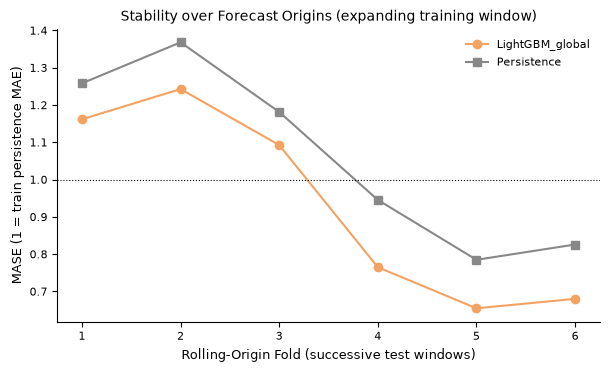

**Kết quả (rolling-origin).** Trên 6 cửa sổ, mô hình thắng persistence ở **6/6** cửa sổ; tỷ lệ MAE cửa sổ xấu nhất / tốt nhất là 1.91. Khác biệt giữa các cửa sổ phản ánh cả mùa (test chạy từ mùa hè đến mùa đông) lẫn độ trôi của dữ liệu, và không thể tách hai yếu tố này chỉ với một năm test.

In [7]:
# 7.1 rolling-origin: sáu cửa sổ liên tiếp phủ giai đoạn test
edges = pd.date_range(TS, test["target_time_utc"].max() + pd.Timedelta(hours=1), periods=7)
folds = []
for i in range(6):
    a, b = edges[i], edges[i + 1]
    tr_r = data[data["target_time_utc"] < a]; te_r = data[(data["target_time_utc"] >= a) & (data["target_time_utc"] < b)]
    if len(te_r) < 200: continue
    m = make_model(SELECTED, seed=0).fit(tr_r[cols_for()], tr_r[Y]); p = m.predict(te_r[cols_for()])
    s_m, s_p = score(te_r[Y], p, te_r[UNIT_COL]), score(te_r[Y], te_r["demand"], te_r[UNIT_COL])
    folds.append({"Fold": i + 1, "Window_Start": a.date(), "Window_End": (b - pd.Timedelta(hours=1)).date(), "Train_Rows": len(tr_r), "Test_Rows": len(te_r),
                  f"MAE_{SELECTED}": s_m["MAE_MW"], "MAE_Persistence": s_p["MAE_MW"], f"MASE_{SELECTED}": s_m["MASE"], "MASE_Persistence": s_p["MASE"]})
roll = pd.DataFrame(folds); roll.round(3).to_csv(f"{REPORT_DIR}/table_nb2_rolling_origin.csv", index=False); display(roll.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(roll["Fold"], roll[f"MASE_{SELECTED}"], marker="o", color=MODEL_COLORS[SELECTED], label=SELECTED)
ax.plot(roll["Fold"], roll["MASE_Persistence"], marker="s", color="#888888", label="Persistence")
ax.axhline(1, color="k", ls=":", lw=0.8)
ax.set_xlabel("Rolling-Origin Fold (successive test windows)"); ax.set_ylabel("MASE (1 = train persistence MAE)")
ax.set_title("Stability over Forecast Origins (expanding training window)"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
savefig(fig, "fig_nb2_rolling_origin")
spread = roll[f"MAE_{SELECTED}"].max() / roll[f"MAE_{SELECTED}"].min(); wins = int((roll[f"MAE_{SELECTED}"] < roll["MAE_Persistence"]).sum())
display(Markdown(f"**Kết quả (rolling-origin).** Trên {len(roll)} cửa sổ, mô hình thắng persistence ở **{wins}/{len(roll)}** cửa sổ; tỷ lệ MAE cửa sổ xấu nhất / tốt nhất là {spread:.2f}. "
                 "Khác biệt giữa các cửa sổ phản ánh cả mùa (test chạy từ mùa hè đến mùa đông) lẫn độ trôi của dữ liệu, và không thể tách hai yếu tố này chỉ với một năm test."))

,Test_Rows,MAE_Final_Model_Seen,MAE_Persistence,MAE_Seen_Raw,MAE_Seen_Normalised,MAE_Unseen_Raw,MAE_Unseen_Normalised,Ratio_Unseen_to_Seen_Raw,Beats_Persistence_Unseen_Raw,Ratio_Unseen_to_Seen_Normalised,Beats_Persistence_Unseen_Normalised
BA_Code,,,,,,,,,,,
AZPS,4424,200.26,203.93,197.14,203.62,198.80,213.86,1.01,True,1.05,False
BPAT,4425,192.38,238.11,194.04,191.33,312.18,200.97,1.61,False,1.05,True
CISO,4233,1014.68,1406.22,1007.52,1052.73,19017.24,1128.81,18.88,False,1.07,True
LDWP,4091,180.21,203.73,181.50,175.08,184.39,180.99,1.02,True,1.03,True
NEVP,4425,189.44,193.85,187.59,189.76,193.16,191.43,1.03,True,1.01,True
PACW,4425,91.79,118.83,92.87,90.22,102.25,91.93,1.10,True,1.02,True
PGE,4425,112.10,134.83,112.99,111.92,114.05,113.68,1.01,True,1.02,True
SRP,4424,212.16,219.38,213.13,216.32,215.21,224.85,1.01,True,1.04,False


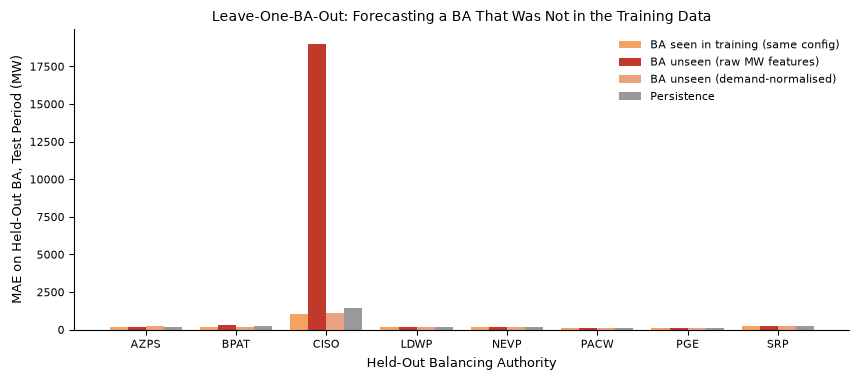

### Kết quả trên BA chưa thấy (giới hạn quan trọng)
* **Biến thể raw (MW):** MAE trên BA chưa thấy gấp 1.01–18.88 lần MAE khi BA đó có trong huấn luyện (trung vị 1.02); thắng persistence ở **6/8** BA bị giữ lại.
* **Biến thể normalised:** tỷ lệ 1.01–1.07 (trung vị 1.04); thắng persistence ở **6/8**.
* **Vì sao hai biến thể khác nhau:** mô hình cây không ngoại suy ra ngoài khoảng MW đã thấy, mà các lag là MW tuyệt đối; BA lớn hoặc nhỏ hơn mọi BA huấn luyện nằm ngoài khoảng đó. Chuẩn hóa theo mean của chính BA giải quyết việc này nhưng giả định BA mới đã có một ít lịch sử.
* **Cách đọc:** bằng chứng về tổng quát hóa sang BA mới là bảng này, **không phải** kết quả test trên BA đã thấy ở mục 5–6. Thí nghiệm giữ lại từng BA trong tám BA của dự án; nó **không** chứng minh khả năng tổng quát hóa sang các BA ngoài tám BA này.

In [8]:
# 7.2 leave-one-BA-out
SCALE_COLS = ["demand"] + LAGS_ORIG + ["y_ma_season", "y_sd_season", "y_diff1"]
ba_mean_train = train.groupby(UNIT_COL)["demand"].mean()
def fit_predict(tr_, te_, normalise):
    """Fit nhẹ trên tr_ và dự báo te_; nếu normalise: chia đặc trưng kiểu demand và target cho mean train của chính BA rồi nhân lại."""
    cols = cols_for(drop_unit=True)
    Xtr, Xte, ytr = tr_[cols].copy(), te_[cols].copy(), tr_[Y].copy()
    if normalise:
        s_tr = tr_[UNIT_COL].map(ba_mean_train); s_te = te_[UNIT_COL].map(ba_mean_train)
        sc = [c for c in cols if c in SCALE_COLS]
        Xtr[sc] = Xtr[sc].div(s_tr, axis=0); Xte[sc] = Xte[sc].div(s_te, axis=0); ytr = ytr / s_tr
    pred = make_model(SELECTED, seed=0, light=True).fit(Xtr, ytr).predict(Xte)
    return pred * s_te.to_numpy() if normalise else pred

seen_pred = {norm: fit_predict(train, test, norm) for norm in (False, True)}      # "seen": huấn luyện có đủ 8 BA, cùng cấu hình
te_ba = test[UNIT_COL].to_numpy(); y_test = test[Y].to_numpy()
rows = []
for held in BA_LIST:
    g = P[P[UNIT_COL] == held]; mk = te_ba == held
    out = {"BA_Code": held, "Test_Rows": int(mk.sum()), "MAE_Final_Model_Seen": np.mean(np.abs(g[SELECTED] - g["y"])), "MAE_Persistence": np.mean(np.abs(g["Persistence"] - g["y"])),
           "MAE_Seen_Raw": np.mean(np.abs(seen_pred[False][mk] - y_test[mk])), "MAE_Seen_Normalised": np.mean(np.abs(seen_pred[True][mk] - y_test[mk]))}
    for lab, norm in [("Raw", False), ("Normalised", True)]:
        pr = fit_predict(train[train[UNIT_COL] != held], test[test[UNIT_COL] == held], norm)
        out[f"MAE_Unseen_{lab}"] = np.mean(np.abs(pr - y_test[mk]))
    rows.append(out)
lobo_tbl = pd.DataFrame(rows).set_index("BA_Code")
for lab in ["Raw", "Normalised"]:
    lobo_tbl[f"Ratio_Unseen_to_Seen_{lab}"] = lobo_tbl[f"MAE_Unseen_{lab}"] / lobo_tbl[f"MAE_Seen_{lab}"]
    lobo_tbl[f"Beats_Persistence_Unseen_{lab}"] = lobo_tbl[f"MAE_Unseen_{lab}"] < lobo_tbl["MAE_Persistence"]
lobo_tbl.round(3).to_csv(f"{REPORT_DIR}/table_nb2_leave_one_ba_out.csv"); display(lobo_tbl.round(2))
check("LOBO holds out each of the eight BAs once", len(lobo_tbl) == 8 and set(lobo_tbl.index) == set(BA_LIST), f"held-out BAs: {lobo_tbl.index.tolist()}")

fig, ax = plt.subplots(figsize=(10, 3.9)); x = np.arange(8); w = 0.2
for j, (c, lab, col) in enumerate([("MAE_Seen_Raw", "BA seen in training (same config)", MODEL_COLORS[SELECTED]), ("MAE_Unseen_Raw", "BA unseen (raw MW features)", "#C0392B"),
                                   ("MAE_Unseen_Normalised", "BA unseen (demand-normalised)", "#E9A27F"), ("MAE_Persistence", "Persistence", "#999999")]):
    ax.bar(x + (j - 1.5) * w, lobo_tbl[c].reindex(BA_LIST), w, color=col, label=lab)
ax.set_xticks(x); ax.set_xticklabels(BA_LIST); ax.set_xlabel("Held-Out Balancing Authority"); ax.set_ylabel("MAE on Held-Out BA, Test Period (MW)")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Leave-One-BA-Out: Forecasting a BA That Was Not in the Training Data"); savefig(fig, "fig_nb2_leave_one_ba_out")

n_beat_raw = int(lobo_tbl["Beats_Persistence_Unseen_Raw"].sum()); n_beat_norm = int(lobo_tbl["Beats_Persistence_Unseen_Normalised"].sum())
display(Markdown(
    "### Kết quả trên BA chưa thấy (giới hạn quan trọng)\n"
    f"* **Biến thể raw (MW):** MAE trên BA chưa thấy gấp {lobo_tbl['Ratio_Unseen_to_Seen_Raw'].min():.2f}–{lobo_tbl['Ratio_Unseen_to_Seen_Raw'].max():.2f} lần MAE khi BA đó có trong huấn luyện (trung vị {lobo_tbl['Ratio_Unseen_to_Seen_Raw'].median():.2f}); thắng persistence ở **{n_beat_raw}/8** BA bị giữ lại.\n"
    f"* **Biến thể normalised:** tỷ lệ {lobo_tbl['Ratio_Unseen_to_Seen_Normalised'].min():.2f}–{lobo_tbl['Ratio_Unseen_to_Seen_Normalised'].max():.2f} (trung vị {lobo_tbl['Ratio_Unseen_to_Seen_Normalised'].median():.2f}); thắng persistence ở **{n_beat_norm}/8**.\n"
    "* **Vì sao hai biến thể khác nhau:** mô hình cây không ngoại suy ra ngoài khoảng MW đã thấy, mà các lag là MW tuyệt đối; BA lớn hoặc nhỏ hơn mọi BA huấn luyện nằm ngoài khoảng đó. Chuẩn hóa theo mean của chính BA giải quyết việc này nhưng giả định BA mới đã có một ít lịch sử.\n"
    "* **Cách đọc:** bằng chứng về tổng quát hóa sang BA mới là bảng này, **không phải** kết quả test trên BA đã thấy ở mục 5–6. Thí nghiệm giữ lại từng BA trong tám BA của dự án; nó **không** chứng minh khả năng tổng quát hóa sang các BA ngoài tám BA này."))

## 8. Mô hình dựa vào đặc trưng nào?

**Câu hỏi.** Dự báo của mô hình được chọn dựa chủ yếu vào đặc trưng nào, và điều đó có hợp lý về mặt vật lý không?
**Cách làm.** Một hình gồm **permutation importance** (tăng MAE khi xáo trộn một đặc trưng, tính trên mẫu test, mô hình-agnostic) và, nếu đã cài `shap` và mô hình là cây, **mean |SHAP|**. Phần SHAP dependence, ổn định top-5 theo seed của bản gốc đã bỏ vì cùng thông điệp. **Importance không phải nhân quả:** lag lớn cho biết mô hình thấy lag đó hữu ích, không phải lag gây ra nhu cầu.

,Feature,MAE_Increase_MW,Std,Meaning
0,demand,1787.73,20.05,demand at issue hour t (MW)
7,y_ma_season,1785.72,40.54,"mean demand, 24 h ending at t"
1,y_lag1,460.88,7.11,demand at t-1 h
5,y_lag48,254.51,6.46,demand at t-48 h
6,y_lag168,231.75,4.60,demand at t-168 h
4,y_lag24,92.30,1.68,demand at t-24 h
11,dow,85.74,2.09,day of week of t (Mon=0)
10,hr,49.45,6.42,UTC hour of t
13,doy,34.28,3.25,day of year of t
8,y_sd_season,21.92,0.84,"std of demand, 24 h ending at t"


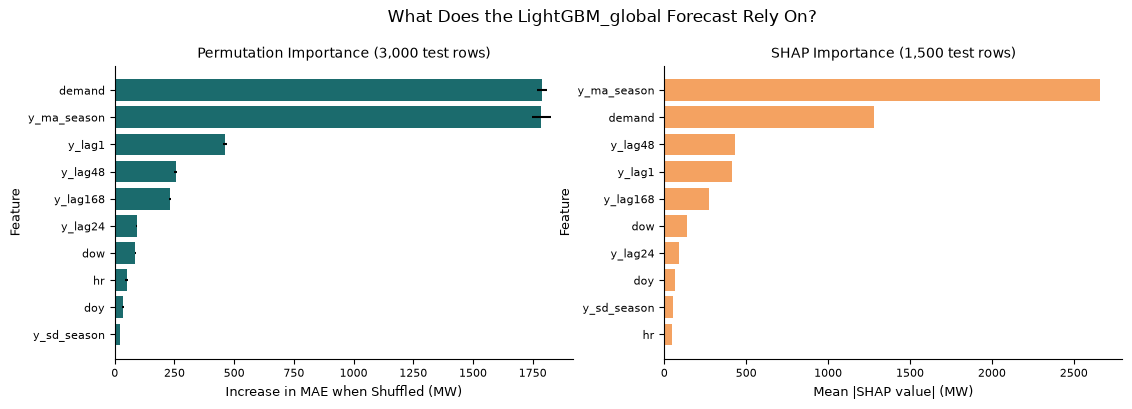

**Kết quả.** Ba đặc trưng quan trọng nhất theo permutation importance là `demand`, `y_ma_season` và `y_lag1`. Biểu đồ SHAP (nếu có) cho thứ tự tương tự hay khác thì xem trực tiếp trên hình. Nếu các đặc trưng gần đây của demand (demand hiện tại, trung bình trượt) đứng đầu, mô hình chủ yếu *hiệu chỉnh* mức nhu cầu hiện tại bằng thông tin lịch; điều này nhất quán với việc persistence là baseline mạnh.

In [9]:
FEATURE_DOC = {"demand": "demand at issue hour t (MW)", "y_lag1": "demand at t-1 h", "y_lag2": "demand at t-2 h", "y_lag3": "demand at t-3 h", "y_lag24": "demand at t-24 h",
               "y_lag48": "demand at t-48 h", "y_lag168": "demand at t-168 h", "y_ma_season": "mean demand, 24 h ending at t", "y_sd_season": "std of demand, 24 h ending at t",
               "y_diff1": "demand(t) - demand(t-1)", "hr": "UTC hour of t", "dow": "day of week of t (Mon=0)", "mon": "month of t", "doy": "day of year of t", "unit_code": "BA identifier"}
cols_sel = cols_for()
rs = np.random.RandomState(SEED); sub = test.iloc[rs.choice(len(test), size=min(3000, len(test)), replace=False)]
perm = permutation_importance(final_model, sub[cols_sel], sub[Y], scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"Feature": cols_sel, "MAE_Increase_MW": perm.importances_mean, "Std": perm.importances_std, "Meaning": [FEATURE_DOC.get(c, c) for c in cols_sel]}).sort_values("MAE_Increase_MW", ascending=False)
imp.round(2).to_csv(f"{REPORT_DIR}/table_nb2_permutation_importance.csv", index=False); display(imp.round(2).head(10))

use_shap = HAS_SHAP and SELECTED in ("RandomForest", "LightGBM_global")
fig, axs = plt.subplots(1, 2 if use_shap else 1, figsize=(13 if use_shap else 7, 3.8)); axs = np.atleast_1d(axs)
top = imp.head(10)[::-1]
axs[0].barh(top["Feature"], top["MAE_Increase_MW"], xerr=top["Std"], color="#1B6B6D")
axs[0].set_xlabel("Increase in MAE when Shuffled (MW)"); axs[0].set_ylabel("Feature"); axs[0].set_title(f"Permutation Importance ({len(sub):,} test rows)")
if use_shap:
    Xs = sub[cols_sel].iloc[:1500]; sv = shap.TreeExplainer(final_model).shap_values(Xs); sv = sv[0] if isinstance(sv, list) else sv
    shap_imp = pd.DataFrame({"Feature": cols_sel, "Mean_Abs_SHAP_MW": np.abs(sv).mean(0)}).sort_values("Mean_Abs_SHAP_MW", ascending=False)
    shap_imp["Share"] = (shap_imp["Mean_Abs_SHAP_MW"] / shap_imp["Mean_Abs_SHAP_MW"].sum()).round(3); shap_imp.round(2).to_csv(f"{REPORT_DIR}/table_nb2_shap.csv", index=False)
    t2 = shap_imp.head(10)[::-1]; axs[1].barh(t2["Feature"], t2["Mean_Abs_SHAP_MW"], color="#F4A261")
    axs[1].set_xlabel("Mean |SHAP value| (MW)"); axs[1].set_ylabel("Feature"); axs[1].set_title("SHAP Importance (1,500 test rows)")
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"What Does the {SELECTED} Forecast Rely On?", y=1.03); savefig(fig, "fig_nb2_feature_importance")
display(Markdown(f"**Kết quả.** Ba đặc trưng quan trọng nhất theo permutation importance là `{imp.Feature.iloc[0]}`, `{imp.Feature.iloc[1]}` và `{imp.Feature.iloc[2]}`. "
                 + ("Biểu đồ SHAP (nếu có) cho thứ tự tương tự hay khác thì xem trực tiếp trên hình. " if use_shap else "Chưa có SHAP (gói chưa cài hoặc mô hình không phải cây) nên chỉ dùng permutation importance. ")
                 + "Nếu các đặc trưng gần đây của demand (demand hiện tại, trung bình trượt) đứng đầu, mô hình chủ yếu *hiệu chỉnh* mức nhu cầu hiện tại bằng thông tin lịch; điều này nhất quán với việc persistence là baseline mạnh."))

# PHẦN B — RQ3: dự báo có dùng được trong vận hành không?

## 9. Khoảng dự báo (split conformal): coverage

**Câu hỏi.** Khoảng dự báo 90% có thực sự phủ giá trị thật khoảng 90% thời gian, tổng thể *và* ở từng BA?
**Cách làm.** Split conformal với sai số tuyệt đối. Mô hình được fit trên target trước `VAL_START`; **cửa sổ validation là tập hiệu chỉnh**; cùng mô hình dự báo test. *Nominal coverage* = 90%; *empirical coverage* đo trên test. Hai biến thể: **pooled** (một phân vị cho mọi BA) và **per-BA** (một phân vị cho mỗi BA). Biến thể "scaled" của bản gốc đã bỏ để gọn.
**Lưu ý.** Bảo đảm của conformal cần hiệu chỉnh và test hoán đổi được; ở đây hiệu chỉnh là mùa xuân còn test là hè đến đông nên có thể bị vi phạm. Kết quả test cho biết coverage có giữ được trong thực tế hay không. Mô hình dùng cho khoảng (fit trước `VAL_START`) khác mô hình cuối (fit trên toàn train), nên MAE của nó được in ra để so.

,Nominal_Coverage,Empirical_Coverage,Coverage_Extreme_Hours,Coverage_Ordinary_Hours,Mean_Width_MW,Min_BA_Coverage,Max_BA_Coverage,Coverage_AZPS,Coverage_BPAT,Coverage_CISO,Coverage_LDWP,Coverage_NEVP,Coverage_PACW,Coverage_PGE,Coverage_SRP
Method,,,,,,,,,,,,,,,
pooled,0.9,0.884,0.749,0.916,1050.299,0.395,0.999,0.931,0.946,0.395,0.949,0.930,0.999,0.983,0.919
per_BA,0.9,0.869,0.708,0.907,1090.478,0.821,0.915,0.905,0.869,0.843,0.845,0.915,0.851,0.821,0.899


Mô hình dùng cho khoảng (fit trước 2024-04-01): MAE test 276.1 MW (mô hình cuối fit trên toàn train: 271.1 MW)


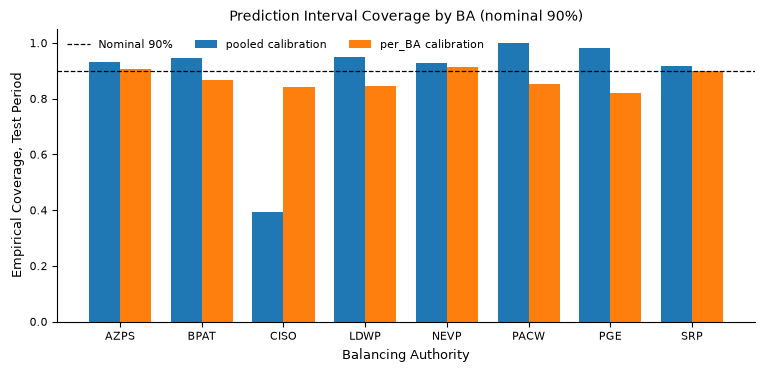

**Kết quả.** Khoảng pooled phủ **88.4%** tổng thể (danh nghĩa 90%), nhưng coverage từng BA nằm từ 39% đến 100% (thấp nhất: CISO). Hiệu chỉnh per-BA cho 82–92%. Trong giờ cực đoan, coverage là 75% (pooled) và 71% (per-BA); giờ thường: 92% và 91%.

**Ý nghĩa cho RQ3.** Cam kết 90% chỉ được ủng hộ ở những chỗ bảng cho coverage gần 90%. Một con số tổng thể không đủ để tuyên bố khoảng dự báo đáng tin: nếu coverage trong giờ cực đoan thấp rõ rệt so với 90%, không nên dùng khoảng này làm biên an toàn cho giờ cao điểm.

In [10]:
ALPHA = 0.10
m_cal = val_models[SELECTED]
cal_res = np.abs(val[Y].to_numpy() - val_pred[SELECTED])
test_pred_cal = m_cal.predict(test[cols_for()])
def conf_q(res, alpha=ALPHA):
    res = np.sort(np.asarray(res)); n = len(res); k = int(np.ceil((n + 1) * (1 - alpha)))
    return res[min(k, n) - 1]
y_te = test[Y].to_numpy()
q_pool = conf_q(cal_res)
q_ba = {b: conf_q(cal_res[val[UNIT_COL].to_numpy() == b]) for b in BA_LIST}
half = {"pooled": np.full(len(test), q_pool), "per_BA": np.array([q_ba[b] for b in te_ba])}
ext_te = (y_te > test[UNIT_COL].map(THR).to_numpy())

rows = []
for nm, hw in half.items():
    cov = (y_te >= test_pred_cal - hw) & (y_te <= test_pred_cal + hw)
    r = {"Method": nm, "Nominal_Coverage": 1 - ALPHA, "Empirical_Coverage": cov.mean(), "Coverage_Extreme_Hours": cov[ext_te].mean(), "Coverage_Ordinary_Hours": cov[~ext_te].mean(),
         "Mean_Width_MW": (2 * hw).mean(), "Min_BA_Coverage": min(cov[te_ba == b].mean() for b in BA_LIST), "Max_BA_Coverage": max(cov[te_ba == b].mean() for b in BA_LIST)}
    for b in BA_LIST: r[f"Coverage_{b}"] = cov[te_ba == b].mean()
    rows.append(r)
conf_tbl = pd.DataFrame(rows).set_index("Method"); conf_tbl.round(3).to_csv(f"{REPORT_DIR}/table_nb2_conformal.csv"); display(conf_tbl.round(3))
print(f"Mô hình dùng cho khoảng (fit trước {VAL_START.date()}): MAE test {np.mean(np.abs(y_te - test_pred_cal)):,.1f} MW (mô hình cuối fit trên toàn train: {overall.loc[SELECTED, 'MAE_MW_mean']:,.1f} MW)")

fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(8); w = 0.38
for j, nm in enumerate(["pooled", "per_BA"]):
    ax.bar(x + (j - 0.5) * w, [conf_tbl.loc[nm, f"Coverage_{b}"] for b in BA_LIST], w, label=f"{nm} calibration")
ax.axhline(1 - ALPHA, color="k", ls="--", lw=0.9, label="Nominal 90%"); ax.set_xticks(x); ax.set_xticklabels(BA_LIST); ax.set_ylim(0, 1.05)
ax.set_xlabel("Balancing Authority"); ax.set_ylabel("Empirical Coverage, Test Period"); ax.set_title("Prediction Interval Coverage by BA (nominal 90%)")
ax.legend(frameon=False, ncol=3, fontsize=8); ax.spines[["top", "right"]].set_visible(False); savefig(fig, "fig_nb2_conformal_coverage")

worst_ba = min(BA_LIST, key=lambda b: conf_tbl.loc["pooled", f"Coverage_{b}"])
display(Markdown(
    f"**Kết quả.** Khoảng pooled phủ **{100 * conf_tbl.loc['pooled', 'Empirical_Coverage']:.1f}%** tổng thể (danh nghĩa 90%), nhưng coverage từng BA nằm từ {100 * conf_tbl.loc['pooled', 'Min_BA_Coverage']:.0f}% đến {100 * conf_tbl.loc['pooled', 'Max_BA_Coverage']:.0f}% (thấp nhất: {worst_ba}). "
    f"Hiệu chỉnh per-BA cho {100 * conf_tbl.loc['per_BA', 'Min_BA_Coverage']:.0f}–{100 * conf_tbl.loc['per_BA', 'Max_BA_Coverage']:.0f}%. "
    f"Trong giờ cực đoan, coverage là {100 * conf_tbl.loc['pooled', 'Coverage_Extreme_Hours']:.0f}% (pooled) và {100 * conf_tbl.loc['per_BA', 'Coverage_Extreme_Hours']:.0f}% (per-BA); giờ thường: {100 * conf_tbl.loc['pooled', 'Coverage_Ordinary_Hours']:.0f}% và {100 * conf_tbl.loc['per_BA', 'Coverage_Ordinary_Hours']:.0f}%.\n\n"
    "**Ý nghĩa cho RQ3.** Cam kết 90% chỉ được ủng hộ ở những chỗ bảng cho coverage gần 90%. Một con số tổng thể không đủ để tuyên bố khoảng dự báo đáng tin: nếu coverage trong giờ cực đoan thấp rõ rệt so với 90%, không nên dùng khoảng này làm biên an toàn cho giờ cao điểm."))

## 10. Cảnh báo giờ cực đoan

**Câu hỏi.** Dự báo có báo trước được các giờ cực đoan không?
**Định nghĩa.** Giờ cực đoan là giờ *thực tế* có demand vượt phân vị 90% của chính BA, **ngưỡng ước lượng chỉ trên target giai đoạn train** (`THR`, định nghĩa như Notebook 1); giờ test chỉ được so với ngưỡng này, không dùng test để chọn ngưỡng.
**Dự báo một giá trị khác với cảnh báo một sự kiện.** MAE đo sai số của con số; cảnh báo là bài toán phân loại. Quy tắc cảnh báo ở đây được **ấn định trước, không tinh chỉnh**: báo động nếu *dự báo* vượt ngưỡng BA (hệ số 1.0). Đánh giá chính gồm precision, recall, F1 và **PR-AUC** (điểm số = dự báo/ngưỡng, không phụ thuộc điểm cắt), cạnh *prevalence* (tỷ lệ giờ cực đoan thật) là mức PR-AUC của một dự đoán ngẫu nhiên. Không vẽ nhiều đường nhạy cảm theo ngưỡng.

,Prevalence,TP,FP,FN,Precision,Recall,F1,PR_AUC
Method,,,,,,,,
LightGBM_global,0.193,5802,765,924,0.884,0.863,0.873,0.949
Persistence,0.193,5799,940,927,0.861,0.862,0.861,0.937
WeeklyNaive,0.193,4890,2162,1836,0.693,0.727,0.710,0.762
EIA_day_ahead,0.193,5780,683,946,0.894,0.859,0.876,0.941


,Extreme_Hours,Share_of_Test_Hours_%,MAE_Extreme_MW,MAE_Ordinary_MW,MAE_Extreme_Persistence_MW,nMAE_Extreme_%,nMAE_Ordinary_%,Bias_Extreme_MW,Recall,Precision,Extreme_to_Ordinary_MAE_Ratio,Model_Beats_Persistence_Extreme
BA_Code,,,,,,,,,,,,
AZPS,1249.0,28.23,284.91,166.96,271.30,4.40,4.35,-34.84,0.94,0.93,1.71,False
BPAT,418.0,9.45,319.71,179.09,323.37,3.80,2.77,-214.18,0.70,0.79,1.79,True
CISO,1101.0,26.01,1703.25,772.62,2035.21,4.82,3.04,-790.52,0.88,0.93,2.20,True
LDWP,570.0,13.93,326.93,156.46,355.79,8.02,6.22,-153.21,0.79,0.83,2.09,True
NEVP,1058.0,23.91,298.24,155.25,292.48,4.09,3.56,-97.27,0.94,0.93,1.92,False
PACW,554.0,12.52,145.82,84.06,153.95,4.49,3.57,-83.66,0.74,0.81,1.73,True
PGE,659.0,14.89,216.65,93.81,223.81,6.38,3.72,-119.80,0.71,0.73,2.31,True
SRP,1117.0,25.25,315.26,177.34,296.51,4.72,4.71,-70.83,0.93,0.93,1.78,False
ALL (8 BAs),6726.0,19.29,511.80,213.40,563.63,4.78,3.49,-207.86,0.86,0.88,2.40,True


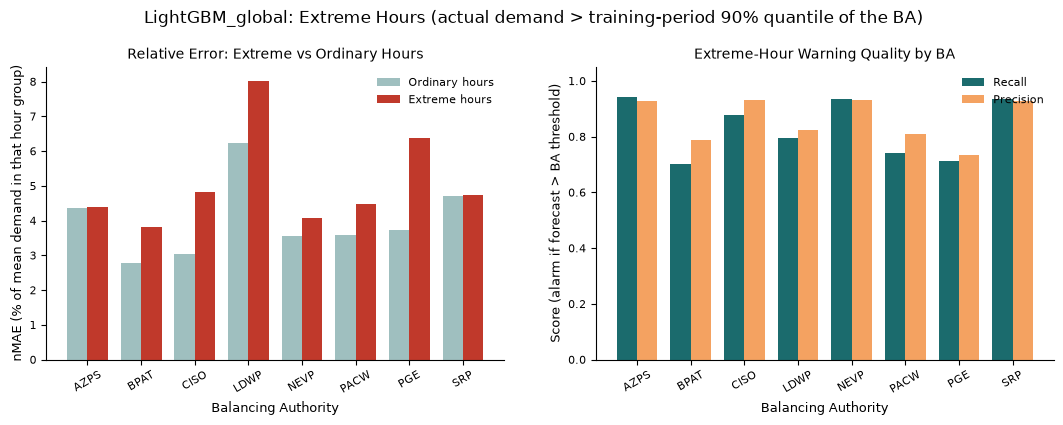

**Kết quả.** Tỷ lệ giờ cực đoan trong test là 19.3% (cao hơn 10% danh nghĩa; số giờ cực đoan mỗi BA nằm từ 418 đến 1,249). Cảnh báo bằng LightGBM_global: precision 0.884, recall 0.863, F1 0.873, PR-AUC 0.949; persistence: precision 0.861, recall 0.862, PR-AUC 0.937. Theo BA, recall của LightGBM_global từ 0.70 (BPAT) đến 0.94. MAE trong giờ cực đoan bằng 1.71–2.31 lần MAE giờ thường (trung vị 1.85). Mô hình không thắng persistence về MAE trong giờ cực đoan ngoại trừ: AZPS, NEVP, SRP (thắng ở các BA còn lại). Bias trung bình trong giờ cực đoan từ -791 đến -35 MW (âm = dự báo thấp hơn thực tế, hướng đáng lo hơn về vận hành).

**Ý nghĩa cho RQ3.** So *prevalence* với precision và PR-AUC trước khi kết luận: tần suất nền cao làm precision dễ trông tốt. Hãy đọc cột nMAE và recall theo từng BA thay vì BA lớn nhất. Chưa đo được lợi ích tiền tệ, dự phòng hay độ tin cậy lưới, nên không tuyên bố các lợi ích đó.

In [11]:
truth = P["ext"].to_numpy(); thr_row = P[UNIT_COL].map(THR)
alarm_methods = [SELECTED, "Persistence", "WeeklyNaive"] + (["EIA_day_ahead"] if full_cov else [])
rows = []
for m in alarm_methods:
    alarm = (P[m] > thr_row).to_numpy(); tp = int((alarm & truth).sum()); fp = int((alarm & ~truth).sum()); fn = int((~alarm & truth).sum())
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    rows.append({"Method": m, "Prevalence": truth.mean(), "TP": tp, "FP": fp, "FN": fn, "Precision": pr, "Recall": rc, "F1": 2 * pr * rc / (pr + rc) if pr + rc else 0.0,
                 "PR_AUC": average_precision_score(truth, (P[m] / thr_row).to_numpy())})
alarm_tbl = pd.DataFrame(rows).set_index("Method"); alarm_tbl.round(3).to_csv(f"{REPORT_DIR}/table_nb2_extreme_alarms.csv"); display(alarm_tbl.round(3))

def ext_stats(mask):
    g = P[mask]; e_, o_ = g[g["ext"]], g[~g["ext"]]
    al = (e_[SELECTED] > e_[UNIT_COL].map(THR)).to_numpy(); alr = (g[SELECTED] > g[UNIT_COL].map(THR)).to_numpy(); tr_ = g["ext"].to_numpy()
    tp, fp = int((alr & tr_).sum()), int((alr & ~tr_).sum())
    return {"Extreme_Hours": len(e_), "Share_of_Test_Hours_%": 100 * len(e_) / len(g),
            "MAE_Extreme_MW": np.mean(np.abs(e_[SELECTED] - e_["y"])), "MAE_Ordinary_MW": np.mean(np.abs(o_[SELECTED] - o_["y"])),
            "MAE_Extreme_Persistence_MW": np.mean(np.abs(e_["Persistence"] - e_["y"])),
            "nMAE_Extreme_%": 100 * np.mean(np.abs(e_[SELECTED] - e_["y"])) / e_["y"].mean(), "nMAE_Ordinary_%": 100 * np.mean(np.abs(o_[SELECTED] - o_["y"])) / o_["y"].mean(),
            "Bias_Extreme_MW": np.mean(e_[SELECTED] - e_["y"]), "Recall": tp / max(int(tr_.sum()), 1), "Precision": tp / max(tp + fp, 1)}
ext_tbl = pd.DataFrame({ba: ext_stats(P[UNIT_COL] == ba) for ba in BA_LIST}).T
ext_tbl.loc["ALL (8 BAs)"] = ext_stats(pd.Series(True, index=P.index))
ext_tbl["Extreme_to_Ordinary_MAE_Ratio"] = ext_tbl["MAE_Extreme_MW"] / ext_tbl["MAE_Ordinary_MW"]
ext_tbl["Model_Beats_Persistence_Extreme"] = ext_tbl["MAE_Extreme_MW"] < ext_tbl["MAE_Extreme_Persistence_MW"]
ext_tbl.index.name = "BA_Code"; ext_tbl.round(3).to_csv(f"{REPORT_DIR}/table_nb2_extreme_by_ba.csv"); display(ext_tbl.round(2))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8)); x = np.arange(8); w = 0.38; e8 = ext_tbl.loc[BA_LIST]
axs[0].bar(x - w / 2, e8["nMAE_Ordinary_%"], w, color="#9FBFBF", label="Ordinary hours"); axs[0].bar(x + w / 2, e8["nMAE_Extreme_%"], w, color="#C0392B", label="Extreme hours")
axs[0].set_ylabel("nMAE (% of mean demand in that hour group)"); axs[0].set_title("Relative Error: Extreme vs Ordinary Hours")
axs[1].bar(x - w / 2, e8["Recall"], w, color="#1B6B6D", label="Recall"); axs[1].bar(x + w / 2, e8["Precision"], w, color="#F4A261", label="Precision")
axs[1].set_ylim(0, 1.05); axs[1].set_ylabel("Score (alarm if forecast > BA threshold)"); axs[1].set_title("Extreme-Hour Warning Quality by BA")
for ax in axs:
    ax.set_xticks(x); ax.set_xticklabels(BA_LIST, rotation=30); ax.set_xlabel("Balancing Authority"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"{SELECTED}: Extreme Hours (actual demand > training-period {EVENT_QUANTILE:.0%} quantile of the BA)", y=1.03); savefig(fig, "fig_nb2_extreme_hours")

a_sel, a_per = alarm_tbl.loc[SELECTED], alarm_tbl.loc["Persistence"]
ratio = e8["Extreme_to_Ordinary_MAE_Ratio"]; worse_ext = e8.index[~e8["Model_Beats_Persistence_Extreme"].astype(bool)].tolist()
display(Markdown(
    f"**Kết quả.** Tỷ lệ giờ cực đoan trong test là {100 * a_sel.Prevalence:.1f}% (cao hơn 10% danh nghĩa; số giờ cực đoan mỗi BA nằm từ {int(e8.Extreme_Hours.min()):,} đến {int(e8.Extreme_Hours.max()):,}). "
    f"Cảnh báo bằng {SELECTED}: precision {a_sel.Precision:.3f}, recall {a_sel.Recall:.3f}, F1 {a_sel.F1:.3f}, PR-AUC {a_sel.PR_AUC:.3f}; persistence: precision {a_per.Precision:.3f}, recall {a_per.Recall:.3f}, PR-AUC {a_per.PR_AUC:.3f}. "
    f"Theo BA, recall của {SELECTED} từ {e8.Recall.min():.2f} ({e8.Recall.idxmin()}) đến {e8.Recall.max():.2f}. MAE trong giờ cực đoan bằng {ratio.min():.2f}–{ratio.max():.2f} lần MAE giờ thường (trung vị {ratio.median():.2f}). "
    f"Mô hình {'thắng' if not worse_ext else 'không thắng'} persistence về MAE trong giờ cực đoan " + ("ở cả tám BA" if not worse_ext else "ngoại trừ: " + ", ".join(worse_ext) + " (thắng ở các BA còn lại)") + ". "
    f"Bias trung bình trong giờ cực đoan từ {e8.Bias_Extreme_MW.min():+.0f} đến {e8.Bias_Extreme_MW.max():+.0f} MW (âm = dự báo thấp hơn thực tế, hướng đáng lo hơn về vận hành).\n\n"
    "**Ý nghĩa cho RQ3.** So *prevalence* với precision và PR-AUC trước khi kết luận: tần suất nền cao làm precision dễ trông tốt. Hãy đọc cột nMAE và recall theo từng BA thay vì BA lớn nhất. Chưa đo được lợi ích tiền tệ, dự phòng hay độ tin cậy lưới, nên không tuyên bố các lợi ích đó."))

## 11. Độ bền theo thời gian (regime change)

**Câu hỏi.** Hiệu quả của mô hình có đổi theo giai đoạn không?
**Cách làm.** Với mô hình cuối *cố định*, sai số theo **tháng của target**: MAE của mô hình và persistence, tỷ số giữa hai bên, bias, và heatmap nMAE theo BA × tháng.
**Không dán nhãn "regime change".** Notebook không có phương pháp phát hiện đổi chế độ với định nghĩa và kiểm định riêng, và dữ liệu test chỉ có sáu tháng. Vì thế đây là **phân tích biến động hiệu suất theo thời gian**; một tháng sai số cao hơn chưa chứng minh có đổi chế độ (có thể chỉ là mùa).

,Hours,MAE_LightGBM_global,MAE_Persistence,Bias_MW,MAE_Ratio_Model_to_Persistence,Change_vs_Previous_Month_%
month,,,,,,
2024-07,5952.0,363.57,417.39,-63.53,0.87,NaN
2024-08,5952.0,336.80,405.68,-32.86,0.83,-7.4
2024-09,5760.0,307.35,380.26,-49.94,0.81,-8.7
2024-10,5952.0,234.21,307.81,-24.38,0.76,-23.8
2024-11,5234.0,186.46,235.63,-14.32,0.79,-20.4
2024-12,5952.0,188.14,255.38,-19.09,0.74,0.9
2025-01,70.0,286.37,257.29,196.97,1.11,52.2


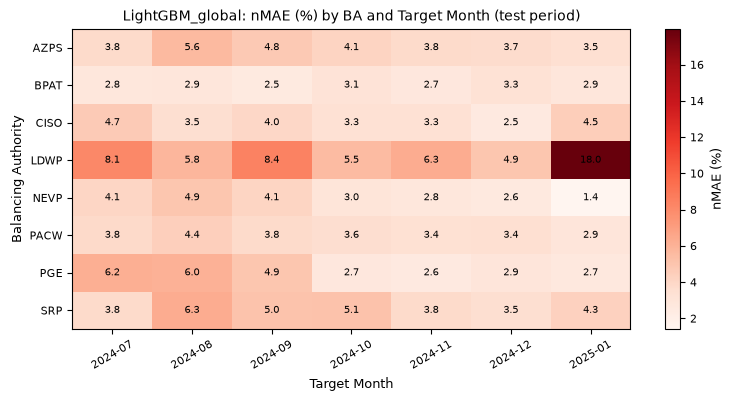

**Kết quả.** Thay đổi MAE giữa hai tháng liên tiếp lớn nhất là 52%. Tỷ số MAE mô hình / persistence theo tháng nằm từ 0.74 (2024-12) đến 1.11 (2025-01); mô hình thắng persistence trong 6/7 tháng. Bias theo tháng từ -64 đến +197 MW.

**Nhận xét cho RQ3.** Đây là biến động hiệu suất theo thời gian, chưa phải phát hiện đổi chế độ. Nếu MAE của cả mô hình *và* persistence cùng giảm hoặc tăng theo tháng thì phần lớn là do mùa, không phải do mô hình xuống cấp; tỷ số MAE và bias ổn định hay trôi mới là tín hiệu cho việc cần huấn luyện lại định kỳ. Kết quả rolling-origin ở mục 7.1 là phép kiểm tra bổ sung với việc fit lại.

In [12]:
P["month"] = P["target_time_utc"].dt.to_period("M").astype(str)
mon = P.groupby("month").apply(lambda g: pd.Series({"Hours": len(g), f"MAE_{SELECTED}": np.mean(np.abs(g[SELECTED] - g["y"])), "MAE_Persistence": np.mean(np.abs(g["Persistence"] - g["y"])),
                                                    "Bias_MW": np.mean(g[SELECTED] - g["y"])}), include_groups=False)
mon["MAE_Ratio_Model_to_Persistence"] = mon[f"MAE_{SELECTED}"] / mon["MAE_Persistence"]
mon["Change_vs_Previous_Month_%"] = (100 * (mon[f"MAE_{SELECTED}"] / mon[f"MAE_{SELECTED}"].shift(1) - 1)).round(1)
mon.round(3).to_csv(f"{REPORT_DIR}/table_nb2_error_by_month.csv"); display(mon.round(2))
hm = P.groupby([UNIT_COL, "month"]).apply(lambda g: 100 * np.mean(np.abs(g[SELECTED] - g["y"])) / g["y"].mean(), include_groups=False).unstack().reindex(BA_LIST)

fig, ax = plt.subplots(figsize=(9, 3.9)); im = ax.imshow(hm.values, aspect="auto", cmap="Reds")
ax.set_yticks(range(8)); ax.set_yticklabels(BA_LIST); ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=30)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax.text(j, i, f"{hm.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_xlabel("Target Month"); ax.set_ylabel("Balancing Authority"); ax.set_title(f"{SELECTED}: nMAE (%) by BA and Target Month (test period)")
fig.colorbar(im, ax=ax, label="nMAE (%)"); savefig(fig, "fig_nb2_error_by_month_ba")

jump = mon["Change_vs_Previous_Month_%"].abs().max(); r_ = mon["MAE_Ratio_Model_to_Persistence"]
display(Markdown(
    f"**Kết quả.** Thay đổi MAE giữa hai tháng liên tiếp lớn nhất là {jump:.0f}%. Tỷ số MAE mô hình / persistence theo tháng nằm từ {r_.min():.2f} ({r_.idxmin()}) đến {r_.max():.2f} ({r_.idxmax()}); mô hình thắng persistence trong {int((r_ < 1).sum())}/{len(r_)} tháng. "
    f"Bias theo tháng từ {mon.Bias_MW.min():+.0f} đến {mon.Bias_MW.max():+.0f} MW.\n\n"
    "**Nhận xét cho RQ3.** Đây là biến động hiệu suất theo thời gian, chưa phải phát hiện đổi chế độ. Nếu MAE của cả mô hình *và* persistence cùng giảm hoặc tăng theo tháng thì phần lớn là do mùa, không phải do mô hình xuống cấp; tỷ số MAE và bias ổn định hay trôi mới là tín hiệu cho việc cần huấn luyện lại định kỳ. Kết quả rolling-origin ở mục 7.1 là phép kiểm tra bổ sung với việc fit lại."))

## 12. CO2 ablation

**Câu hỏi.** Thêm các đặc trưng CO2 có làm dự báo tốt hơn không?
**Cách làm.** Hai bộ đặc trưng, cùng mô hình, **cùng dòng train/test** (chỉ các dòng có đủ CO2 ở cả hai bộ), cùng target, cùng metric: *Without CO2* = `F_ORIG`; *With CO2* = `F_ORIG` + các cột CO2 (CO2 tại *t* và lag 24 giờ, đều có sẵn tại thời điểm phát hành). Chạy với nhiều seed (biến `SEEDS`) để tách tác động của đặc trưng khỏi nhiễu seed; thêm bootstrap theo ngày cho chênh lệch MAE (seed đầu tiên).
**Diễn giải.** CO2 được tính từ cơ cấu phát điện nên không phải nguyên nhân của nhu cầu. Nếu CO2 không cải thiện, kết luận chỉ là *chưa tìm thấy bằng chứng CO2 giúp dự báo trong thiết lập này* (một họ mô hình, một giai đoạn test), không phải "CO2 vô giá trị nói chung". Các ablation lịch/`unit_code`/lag144 của bản gốc đã bỏ vì không thuộc câu hỏi RQ3.

In [13]:
tr_c, te_c = train.dropna(subset=SECONDARY), test.dropna(subset=SECONDARY)
abl_seeds = SEEDS if SELECTED in STOCHASTIC else [0]
co2_ok = len(tr_c) > 1000 and len(te_c) > 1000
if not co2_ok:
    print("Quá ít dòng có dữ liệu CO2 để chạy ablation.")
    abl_sum, abl_ci = None, None
else:
    variants = {"Without CO2 (F_ORIG)": F_ORIG, "With CO2 (F_ORIG + CO2 features)": F_ORIG + SECONDARY}
    rows, preds = [], {}
    for k, v in variants.items():
        for s in abl_seeds:
            m = make_model(SELECTED, seed=s).fit(tr_c[v], tr_c[Y]); p = m.predict(te_c[v])
            rows.append({"Variant": k, "Seed": s, **score(te_c[Y], p, te_c[UNIT_COL])})
            if s == abl_seeds[0]: preds[k] = p
    abl = pd.DataFrame(rows); abl.to_csv(f"{REPORT_DIR}/table_nb2_co2_ablation_by_seed.csv", index=False)
    abl_sum = abl.groupby("Variant").agg(Train_Rows=("n", lambda s: len(tr_c)), Test_Rows=("n", "first"), MAE_MW_Mean=("MAE_MW", "mean"), MAE_MW_Std=("MAE_MW", "std"),
                                         RMSE_MW_Mean=("RMSE_MW", "mean"), MASE_Mean=("MASE", "mean"), Seeds=("Seed", "nunique")).loc[list(variants)]
    base_mae = abl_sum.loc["Without CO2 (F_ORIG)", "MAE_MW_Mean"]
    abl_sum["MAE_Change_vs_Without_CO2_%"] = 100 * (abl_sum["MAE_MW_Mean"] / base_mae - 1)
    abl_sum.round(3).to_csv(f"{REPORT_DIR}/table_nb2_co2_ablation.csv"); display(abl_sum.round(3))
    (lo, mid, hi), nd = day_bootstrap(preds["With CO2 (F_ORIG + CO2 features)"] - te_c[Y].to_numpy(), preds["Without CO2 (F_ORIG)"] - te_c[Y].to_numpy(), te_c["target_time_utc"])
    abl_ci = {"median": mid, "lo": lo, "hi": hi, "days": nd}
    print(f"MAE(with CO2) - MAE(without CO2), seed {abl_seeds[0]}: trung vị {mid:+.1f} MW, CI 95% theo ngày [{lo:+.1f}, {hi:+.1f}] trên {nd} ngày")
    chg = float(abl_sum.loc["With CO2 (F_ORIG + CO2 features)", "MAE_Change_vs_Without_CO2_%"])
    noise = float(abl_sum["MAE_MW_Std"].fillna(0).max())
    verdict = ("CO2 **cải thiện** MAE (CI dưới 0)" if hi < 0 else ("CO2 **làm xấu** MAE (CI trên 0)" if lo > 0 else
               "**chưa tìm thấy bằng chứng** CO2 giúp cải thiện dự báo trong thiết lập này (CI chứa 0)"))
    display(Markdown(f"**Kết quả.** Trên {len(te_c):,} dòng test có CO2 ({len(tr_c):,} dòng train), thêm CO2 đổi MAE trung bình theo seed **{chg:+.2f}%** (std theo seed lớn nhất ≈ {noise:.1f} MW). Bootstrap theo ngày: {verdict}. "
                     "Kết luận chỉ áp dụng cho mô hình và giai đoạn test này, không suy rộng ra mọi mô hình hay dữ liệu."))

,Train_Rows,Test_Rows,MAE_MW_Mean,MAE_MW_Std,RMSE_MW_Mean,MASE_Mean,Seeds,MAE_Change_vs_Without_CO2_%
Variant,,,,,,,,
Without CO2 (F_ORIG),171766,34245,271.903,0.260,557.675,0.917,5,0.000
With CO2 (F_ORIG + CO2 features),171766,34245,274.467,0.478,567.226,0.923,5,0.943


MAE(with CO2) - MAE(without CO2), seed 0: trung vị +1.9 MW, CI 95% theo ngày [-2.0, +5.8] trên 185 ngày


**Kết quả.** Trên 34,245 dòng test có CO2 (171,766 dòng train), thêm CO2 đổi MAE trung bình theo seed **+0.94%** (std theo seed lớn nhất ≈ 0.5 MW). Bootstrap theo ngày: **chưa tìm thấy bằng chứng** CO2 giúp cải thiện dự báo trong thiết lập này (CI chứa 0). Kết luận chỉ áp dụng cho mô hình và giai đoạn test này, không suy rộng ra mọi mô hình hay dữ liệu.

### Nhận xét về ảnh hưởng của biến CO₂

Kết quả ablation study cho thấy việc bổ sung các đặc trưng cường độ CO₂ không cải thiện rõ rệt khả năng dự báo nhu cầu điện. Cụ thể, khi loại bỏ bốn đặc trưng CO₂, MAE của Random Forest giảm từ 277.98 MW xuống 277.54 MW, tương ứng giảm khoảng 0.16%. Điều này cho thấy các đặc trưng CO₂ không mang lại lợi ích dự báo đáng kể trong thí nghiệm này.

Ngược lại, khi loại bỏ các đặc trưng lịch như giờ, thứ trong tuần, tháng và ngày trong năm, MAE tăng từ 277.98 MW lên 323.13 MW, tương ứng tăng khoảng 16.24%. Kết quả cho thấy các đặc trưng lịch đóng góp nhiều hơn vào khả năng dự báo so với các đặc trưng CO₂ trong mô hình được đánh giá.

**Kết luận:** Trong phạm vi dữ liệu và mô hình được thử nghiệm, chưa có bằng chứng rõ ràng rằng các đặc trưng cường độ CO₂ giúp cải thiện dự báo nhu cầu điện. Tuy nhiên, điều này không có nghĩa là CO₂ không có mối quan hệ với nhu cầu điện; kết quả chỉ cho thấy việc bổ sung các biến CO₂ chưa cải thiện hiệu suất dự báo trong thí nghiệm hiện tại.

## 13. Giới hạn và cách một đơn vị vận hành có thể dùng kết quả

* Đánh giá là **dự báo điểm của một giờ đích (t + 24) tại mọi origin theo giờ, cho tám BA miền Tây, trên một giai đoạn test nửa năm**. Không phải một lần nộp dự báo day-ahead gồm 24 giá trị mỗi ngày, cũng không đánh giá horizon khác.
* Mô hình được so với persistence (trùng "same hour yesterday" ở horizon này), weekly naive và dự báo EIA. So với EIA là theo *giờ đích*, hai dự báo không cùng thời điểm phát hành.
* Kết quả giờ cực đoan dựa trên ngưỡng từ target train; giai đoạn test mùa hè đến mùa đông gắn nhãn cực đoan nhiều hơn 10% danh nghĩa ở một số BA, nên đọc precision cùng prevalence.
* LOBO chỉ nói về tám BA của dự án; nó không chứng minh tổng quát hóa sang BA khác. Coverage ở mục 9 giới hạn mức tin cậy của các khoảng dự báo.
* **Chưa đo:** giá trị tiền tệ, tiết kiệm dự phòng, độ tin cậy lưới, hay tác động tới điều độ. Không tuyên bố điều nào trong số đó.
* **Hạn chế khác:** không có dữ liệu thời tiết (nhiệt độ là yếu tố chính của biến thiên tải); một giai đoạn test; không có ngày lễ; dòng thiếu dữ liệu bị loại (xem bảng theo BA); kết quả `LightGBM`/SHAP phụ thuộc gói đã cài; bootstrap theo ngày không tính phụ thuộc giữa các BA.

**Cách dùng có điều kiện** (theo các bảng ở trên): làm benchmark dữ liệu cho dự báo day-ahead; quyết định BA và giờ nào mô hình đáng tin (bảng theo BA, giờ cực đoan); và chỉ dùng khoảng dự báo ở nơi coverage đo được ủng hộ.

## 14. Kết luận (sinh từ kết quả) và bảng kiểm tra

In [14]:
n_beat_bas = int(per_ba_main["Model_Beats_Persistence"].sum())
co2_line = ("Không chạy được CO2 ablation (quá ít dòng có CO2)." if not co2_ok else
            f"**CO2 ablation:** thay đổi MAE {chg:+.2f}% khi thêm CO2; {verdict}.")
parts = [
 "### RQ2 — dự báo 24 giờ so với naive baseline, theo thời gian và trên BA chưa thấy",
 f"**1. Tổng thể.** Trên {len(test):,} giờ test của tám BA ({test['target_time_utc'].min().date()} đến {test['target_time_utc'].max().date()}), mô hình chọn trên validation ({SELECTED}) có MAE {sel.MAE_MW_mean:,.0f} MW so với {pers.MAE_MW_mean:,.0f} MW của persistence (MASE {sel.MASE_mean:.2f}). "
 f"Bootstrap theo ngày cho chênh lệch MAE so với persistence: {ci_tbl.iloc[0].MAE_Difference_MW_Median:+.0f} MW (CI 95% {ci_tbl.iloc[0].CI95_Low:+.0f} đến {ci_tbl.iloc[0].CI95_High:+.0f}).",
 f"**2. Theo BA.** Thắng persistence về MAE ở {n_beat_bas}/8 BA; sai số tương đối từ {diag['nMAE_%'].min():.2f}% ({diag['nMAE_%'].idxmin()}) đến {diag['nMAE_%'].max():.2f}% ({diag['nMAE_%'].idxmax()}); BA khó nhất: {hardest}.",
 f"**3. Theo thời gian.** Thắng persistence ở {wins}/{len(roll)} cửa sổ rolling-origin.",
 f"**4. BA chưa thấy.** Thắng persistence ở {n_beat_raw}/8 (raw) và {n_beat_norm}/8 (normalised) trường hợp giữ lại từng BA; chỉ xét tám BA của dự án.",
 "### RQ3 — dùng trong vận hành",
 f"**5. Khoảng dự báo.** Coverage danh nghĩa 90%; thực tế pooled {100 * conf_tbl.loc['pooled', 'Empirical_Coverage']:.0f}% tổng thể (theo BA {100 * conf_tbl.loc['pooled', 'Min_BA_Coverage']:.0f}–{100 * conf_tbl.loc['pooled', 'Max_BA_Coverage']:.0f}%, giờ cực đoan {100 * conf_tbl.loc['pooled', 'Coverage_Extreme_Hours']:.0f}%); per-BA {100 * conf_tbl.loc['per_BA', 'Min_BA_Coverage']:.0f}–{100 * conf_tbl.loc['per_BA', 'Max_BA_Coverage']:.0f}% (giờ cực đoan {100 * conf_tbl.loc['per_BA', 'Coverage_Extreme_Hours']:.0f}%).",
 f"**6. Cảnh báo giờ cực đoan.** Với prevalence {100 * a_sel.Prevalence:.0f}%: precision {a_sel.Precision:.2f}, recall {a_sel.Recall:.2f}, PR-AUC {a_sel.PR_AUC:.2f} (persistence: {a_per.Precision:.2f}, {a_per.Recall:.2f}, {a_per.PR_AUC:.2f}).",
 f"**7. Độ bền theo thời gian.** Mô hình thắng persistence trong {int((r_ < 1).sum())}/{len(r_)} tháng test; đây là phân tích biến động hiệu suất, chưa phải phát hiện đổi chế độ.",
 f"**8.** {co2_line}",
 "**9. Phạm vi và giới hạn.** Một giờ đích mỗi origin, một giai đoạn test nửa năm, không có thời tiết, không đo lợi ích tiền tệ hay độ tin cậy.",
]
display(Markdown("\n\n".join(parts)))
json.dump({"selected_model": SELECTED, "test_rows": int(len(test)), "overall_mae_mw": float(sel.MAE_MW_mean), "persistence_mae_mw": float(pers.MAE_MW_mean)},
          open(f"{REPORT_DIR}/nb2_results_summary.json", "w"), indent=2)

### RQ2 — dự báo 24 giờ so với naive baseline, theo thời gian và trên BA chưa thấy

**1. Tổng thể.** Trên 34,872 giờ test của tám BA (2024-07-01 đến 2025-01-01), mô hình chọn trên validation (LightGBM_global) có MAE 271 MW so với 335 MW của persistence (MASE 0.92). Bootstrap theo ngày cho chênh lệch MAE so với persistence: -64 MW (CI 95% -80 đến -49).

**2. Theo BA.** Thắng persistence về MAE ở 8/8 BA; sai số tương đối từ 2.89% (BPAT) đến 6.59% (LDWP); BA khó nhất: SRP.

**3. Theo thời gian.** Thắng persistence ở 6/6 cửa sổ rolling-origin.

**4. BA chưa thấy.** Thắng persistence ở 6/8 (raw) và 6/8 (normalised) trường hợp giữ lại từng BA; chỉ xét tám BA của dự án.

### RQ3 — dùng trong vận hành

**5. Khoảng dự báo.** Coverage danh nghĩa 90%; thực tế pooled 88% tổng thể (theo BA 39–100%, giờ cực đoan 75%); per-BA 82–92% (giờ cực đoan 71%).

**6. Cảnh báo giờ cực đoan.** Với prevalence 19%: precision 0.88, recall 0.86, PR-AUC 0.95 (persistence: 0.86, 0.86, 0.94).

**7. Độ bền theo thời gian.** Mô hình thắng persistence trong 6/7 tháng test; đây là phân tích biến động hiệu suất, chưa phải phát hiện đổi chế độ.

**8.** **CO2 ablation:** thay đổi MAE +0.94% khi thêm CO2; **chưa tìm thấy bằng chứng** CO2 giúp cải thiện dự báo trong thiết lập này (CI chứa 0).

**9. Phạm vi và giới hạn.** Một giờ đích mỗi origin, một giai đoạn test nửa năm, không có thời tiết, không đo lợi ích tiền tệ hay độ tin cậy.

In [15]:
# kiểm tra cuối: mỗi phép kiểm tra ghi kèm bằng chứng
check("Metric computation agrees with scikit-learn", abs(score(P["y"], P[SELECTED], P[UNIT_COL])["MAE_MW"] - mean_absolute_error(P["y"], P[SELECTED])) < 1e-9, "MAE from score() == sklearn mean_absolute_error")
check("Extreme thresholds from training targets only", bool(np.allclose(THR.to_numpy(), train.groupby(UNIT_COL)[Y].quantile(EVENT_QUANTILE).reindex(BA_LIST).to_numpy())), "quantiles computed on `train` (target_time_utc < TEST_START)")
check("Per-BA evaluation covers all eight BAs", set(pb["BA_Code"]) == set(BA_LIST) and len(per_ba_main) == 8, f"{sorted(set(pb['BA_Code']))}")
check("Models evaluated on identical rows", len(P) == len(test) and all(P[c].notna().all() for c in MODELS + BASELINES), f"{len(P):,} rows")
check("Conformal calibration uses validation only (no test targets)", val["target_time_utc"].max() < TS, f"calibration targets end {val['target_time_utc'].max()} < test start {TS}")
val_df = pd.DataFrame(VALIDATION); val_df.to_csv(f"{REPORT_DIR}/validation_notebook2.csv", index=False); display(val_df)

,Validation_Check,Status,Evidence,Remaining_Issue
0,Feature file matches manifest checksum,PASS,md5 bef1e94a... == manifest bef1e94a...,Chạy lại Notebook 1 nếu lỗi; không sửa file bằ...
1,Exactly eight BAs in the manifest,PASS,"['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP', 'PACW...",
2,Feature table contains exactly the manifest BAs,PASS,"BAs in table: ['AZPS', 'BPAT', 'CISO', 'LDWP',...",
3,Horizon and test start as in the original project,PASS,"HORIZONS=[24], TEST_START=2024-07-01",
4,All declared feature columns exist,PASS,missing: [],
5,Feature columns are the manifest's primary fea...,PASS,F_ORIG subset of manifest.primary_features,
6,Train/validation/test are time-ordered and dis...,PASS,fit < 2024-04-01 <= validation < 2024-07-01 <=...,
7,Target = demand at t+24h re-verified on loaded...,PASS,"210,002 rows, all eight BAs",
8,All eight BAs have eligible test rows,PASS,"eligible test rows per BA: 4,091-4,425",Dòng không đủ điều kiện là origin có 168 giờ l...
9,y_lag24 is demand 24 h before the issue hour (...,PASS,"209,998 rows verified by timestamp merge; henc...",
